# PROJETO:
#***CLASSIFICAÇÃO DE FALHA EM MÁQUINAS ROTATIVAS COM***
#***APRENDIZADO DE MÁQUINA CLÁSSICO E REDE NEURAL ARTIFICIAL A***
#***PARTIR DE SINAIS DE VIBRAÇÃO***

# ALUNO: JOSÉ LUIZ LOPES

# ENTREGA 05



# PARTE 01 - DADOS TRATADOS E TRANSFORMAÇÕES

# Importação das Bibliotecas

In [ ]:
# --- IMPORTAÇÃO DE BIBLIOTECAS ---

# Biblioteca para download automático de datasets do Kaggle
import kagglehub

# Manipulação de arquivos e caminhos do sistema operacional
import os

# Processamento numérico e manipulação de arrays (essencial para sinais)
import numpy as np

# Estruturação de dados em DataFrames (tabelas para a IA)
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d import Axes3D # Import for 3D plots

import seaborn as sns

# Leitura de arquivos binários do MATLAB (.mat)
from scipy.io import loadmat

# Ferramentas para Transformada de Fourier (Análise de Frequência)
from scipy.fft import fft, fftfreq

# Transformada de Hilbert (Útil para análise de envelope em vibrações)
from scipy.signal import hilbert

from scipy.stats import kurtosis

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder # Ferramentas para escalonamento e codificação de variáveis [cite: 27]
from sklearn.cluster import KMeans # Algoritmo de aprendizado não supervisionado para agrupamento [cite: 35]

from sklearn.decomposition import PCA # Técnica de redução de dimensionalidade para análise de componentes [cite: 35]

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.metrics import  classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score, silhouette_score
from sklearn.utils import resample

# IMPORTAÇÃO DOS CLASSIFICADORES
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC




In [ ]:
import random
import numpy as np
import torch
import os

def set_seed(seed=42):
    """Fixa as sementes de todas as bibliotecas para garantir a reprodutibilidade."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # Se usar multi-GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Semente global fixada em: {seed}")

# Executa a função no início do notebook
set_seed(42)

Semente global fixada em: 42


# Download do dataset do Kaggle

In [ ]:
# --- DOWNLOAD DO DATASET ---

# O comando abaixo baixa a versão mais recente do dataset de Sumair Aziz.
# O caminho (path) retornado aponta para o local onde os arquivos .mat foram salvos.
path = kagglehub.dataset_download("sumairaziz/vibration-faults-dataset-for-rotating-machines")

print(f"Dataset baixado com sucesso em: {path}")

Using Colab cache for faster access to the 'vibration-faults-dataset-for-rotating-machines' dataset.
Dataset baixado com sucesso em: /kaggle/input/vibration-faults-dataset-for-rotating-machines


# Inspeção dos Dados Brutos (.mat)


In [ ]:
# 1. Definir caminhos para as pastas
healthy_dir = os.path.join(path, "Healthy")
faulty_dir = os.path.join(path, "Faulty")

# 2. Definir os nomes dos arquivos específicos a serem inspecionados
file_h_specific = "H26.mat"
file_f_specific = "F46.mat"

def inspecionar_mat_bruto(file_path, label):
    # Carrega o arquivo MATLAB
    raw_data = loadmat(file_path)

    # Filtra as chaves para encontrar a que contém os dados (ignora metadados __)
    data_key = [k for k in raw_data.keys() if not k.startswith('__')][0]

    # Extrai a matriz de dados
    matrix = raw_data[data_key]

    # Converte para DataFrame sem alterar valores
    df = pd.DataFrame(matrix)

    print(f"\n" + "="*50)
    print(f"--- INSPEÇÃO TÉCNICA ({label}) ---")
    print(f"Arquivo: {os.path.basename(file_path)}")
    print(f"Chave no .mat: '{data_key}'")
    print(f"Formato: {matrix.shape}")
    print("="*50)

    # Exibe as estatísticas básicas (Média, Desvio Padrão, Min, Max, Quartis)
    print(f"\nESTATÍSTICA DESCRITIVA ({label}):")
    print(df.describe())
    print("="*50)

    print(f"\nPRIMEIRAS LINHAS ({label}):")
    return df.head()

# Executar inspeção com os arquivos específicos
print(inspecionar_mat_bruto(os.path.join(healthy_dir, file_h_specific), "HEALTHY"))
print(inspecionar_mat_bruto(os.path.join(faulty_dir, file_f_specific), "FAULTY"))


--- INSPEÇÃO TÉCNICA (HEALTHY) ---
Arquivo: H26.mat
Chave no .mat: 'H'
Formato: (5000, 3)

ESTATÍSTICA DESCRITIVA (HEALTHY):
                 0            1            2
count  5000.000000  5000.000000  5000.000000
mean     -0.001283     0.001618    -0.000438
std       0.969062     1.006508     0.989703
min      -3.092217    -2.983284    -3.797709
25%      -0.659826    -0.703187    -0.578096
50%      -0.053669    -0.010739     0.125968
75%       0.622368     0.690968     0.737039
max       2.955439     3.839070     1.470978

PRIMEIRAS LINHAS (HEALTHY):
          0         1         2
0 -0.896128 -1.192358 -0.543226
1 -0.399899 -0.326784  0.288703
2 -1.283066 -0.853074  0.348468
3  1.838931 -1.030439  0.929648
4  0.354678 -0.184128 -1.919786

--- INSPEÇÃO TÉCNICA (FAULTY) ---
Arquivo: F46.mat
Chave no .mat: 'H'
Formato: (5000, 3)

ESTATÍSTICA DESCRITIVA (FAULTY):
                 0            1            2
count  5000.000000  5000.000000  5000.000000
mean     -0.002870     0.002165   

# Sinal da Vibração Saudável e com Falha no tempo



In [ ]:
def plotar_vibracao_triaxial(file_path, label):
    # 1. Carregar dados
    raw_data = loadmat(file_path)
    data_key = [k for k in raw_data.keys() if not k.startswith('__')][0]
    matrix = raw_data[data_key]

    # Se estiver transposto, corrigimos para ter as colunas como eixos
    if matrix.shape[0] < matrix.shape[1]:
        matrix = matrix.T

    # 2. Criar vetor de tempo (assumindo fs=1000Hz)
    fs = 1000
    tempo = np.linspace(0, len(matrix)/fs, len(matrix))

    # 3. Plotagem
    plt.figure(figsize=(15, 5))
    plt.plot(tempo, matrix[:, 0], label='Eixo X', color='blue', alpha=0.7)
    plt.plot(tempo, matrix[:, 1], label='Eixo Y', color='green', alpha=0.7)
    plt.plot(tempo, matrix[:, 2], label='Eixo Z', color='red', alpha=0.7)

    plt.title(f"Sinal de Vibração no Tempo - Condição: {label} ({os.path.basename(file_path)})")
    plt.xlabel("Tempo (segundos)")
    plt.ylabel("Amplitude de Vibração")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ylim(-4, 4) # Ajustar a escala do eixo Y entre 0 e 5
    plt.show()

# Definir arquivos para visualização (usando H26 e F46 conforme solicitado)
healthy_sample = os.path.join(healthy_dir, "H26.mat")
faulty_sample = os.path.join(faulty_dir, "F46.mat")

# As chamadas para a função plotar_vibracao_triaxial serão movidas para células separadas abaixo.


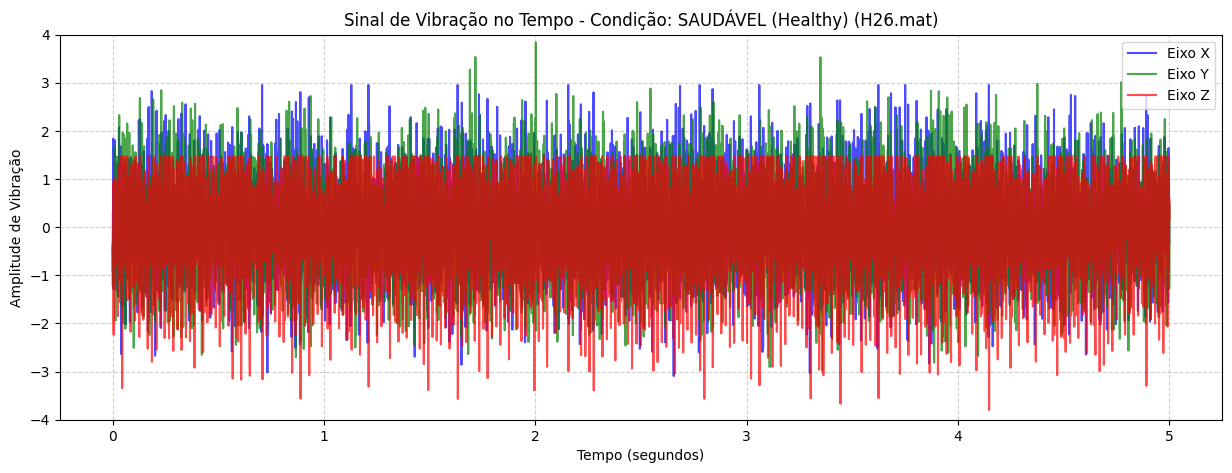

In [ ]:
plotar_vibracao_triaxial(healthy_sample, "SAUDÁVEL (Healthy)")

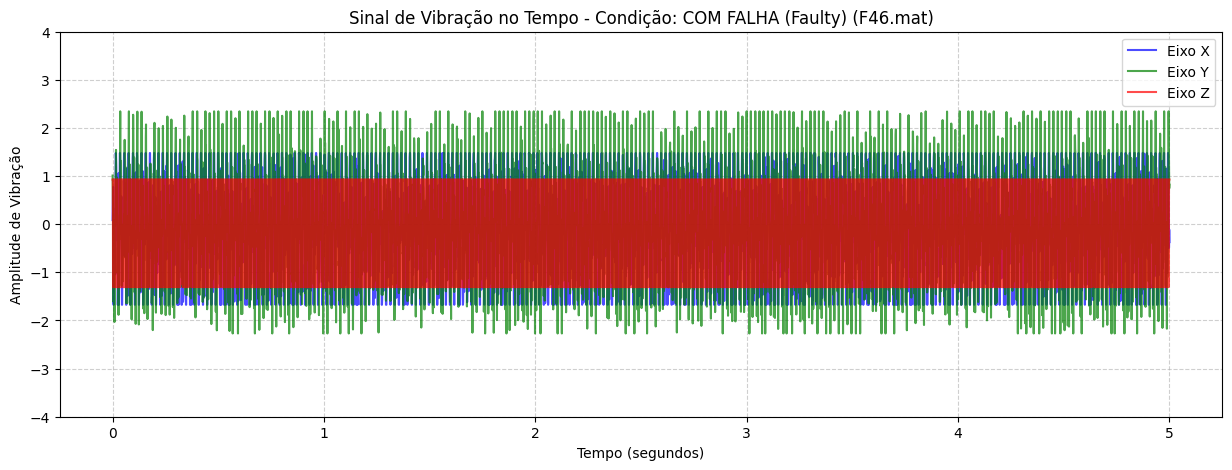

In [ ]:
plotar_vibracao_triaxial(faulty_sample, "COM FALHA (Faulty)")

# Sinal da Vibração Saudável e com Falha depois da Resultante Euclidiana


In [ ]:
def plotar_resultante_euclidiana(file_path, label, plot_color='purple', fs=1000):
    # 1. Carregar dados do arquivo MAT
    raw_data = loadmat(file_path)
    # Filtra chaves internas do MATLAB (__header__, __version__, etc.)
    data_key = [k for k in raw_data.keys() if not k.startswith('__')][0]
    matrix = raw_data[data_key]

    # Garantir formato (Amostras nas linhas, Eixos nas colunas)
    if matrix.shape[0] < matrix.shape[1]:
        matrix = matrix.T

    # 2. Cálculo otimizado da Magnitude (Norma Euclidiana) ao longo das colunas (eixo 1)
    magnitude = np.linalg.norm(matrix[:, :3], axis=1)

    # 3. Vetor de tempo exato por amostragem
    n_amostras = len(magnitude)
    tempo = np.arange(n_amostras) / fs

    # 4. Exibição do gráfico
    plt.figure(figsize=(15, 5))
    plt.plot(tempo, magnitude, label='Resultante Euclidiana', color=plot_color, alpha=0.8)

    filename = os.path.basename(file_path)
    plt.title(f"Resultante Euclidiana no Tempo - Condição: {label} ({filename})")
    plt.xlabel("Tempo (segundos)")
    plt.ylabel("Amplitude da Resultante Euclidiana")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ylim(0, 5)
    plt.show()

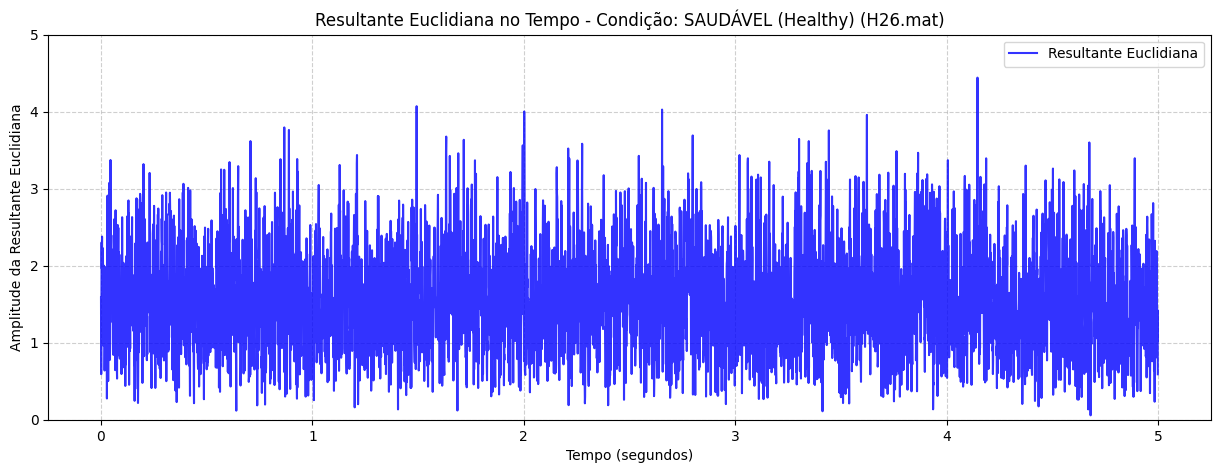

In [ ]:
plotar_resultante_euclidiana(healthy_sample, "SAUDÁVEL (Healthy)", plot_color='blue')

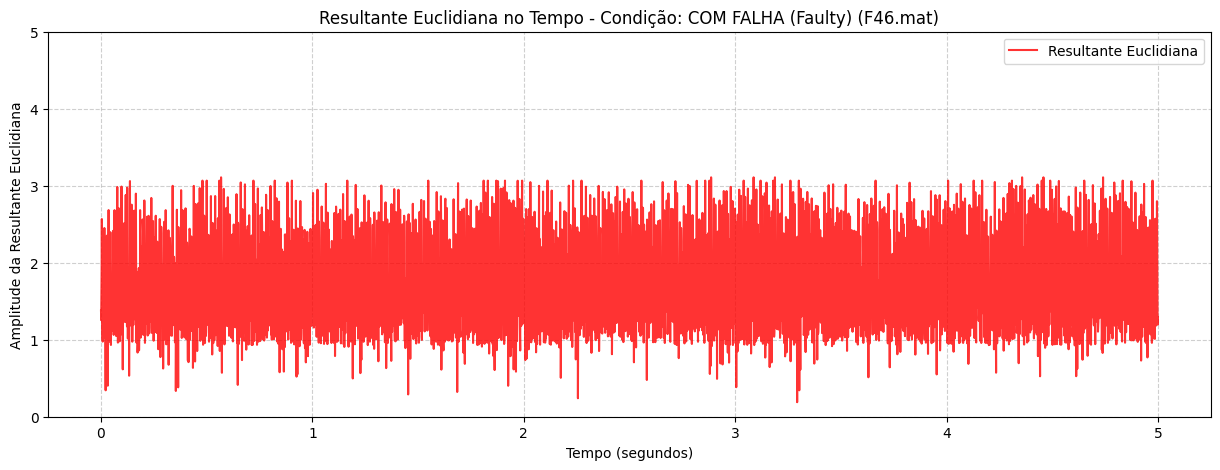

In [ ]:
plotar_resultante_euclidiana(faulty_sample, "COM FALHA (Faulty)", plot_color='red')

# Análise do Domínio da Frequência


      EXTRAÇÃO DE VALORES: ANÁLISE ESPECTRAL (HARMÔNICAS)
CONDIÇÃO: Saudável (Healthy) (H26.mat)
-> Harmônica 1X [49.6-49.9 Hz]: Maior Pico em 49.80 Hz | Amplitude: 0.1494
------------------------------------------------------------
CONDIÇÃO: Falha (Faulty) (F46.mat)
-> Harmônica 2X [99.1-99.4 Hz]: Maior Pico em 99.12 Hz | Amplitude: 0.1186
-> Harmônica 3X [148.9-149.1 Hz]: Maior Pico em 148.93 Hz | Amplitude: 0.2122
------------------------------------------------------------


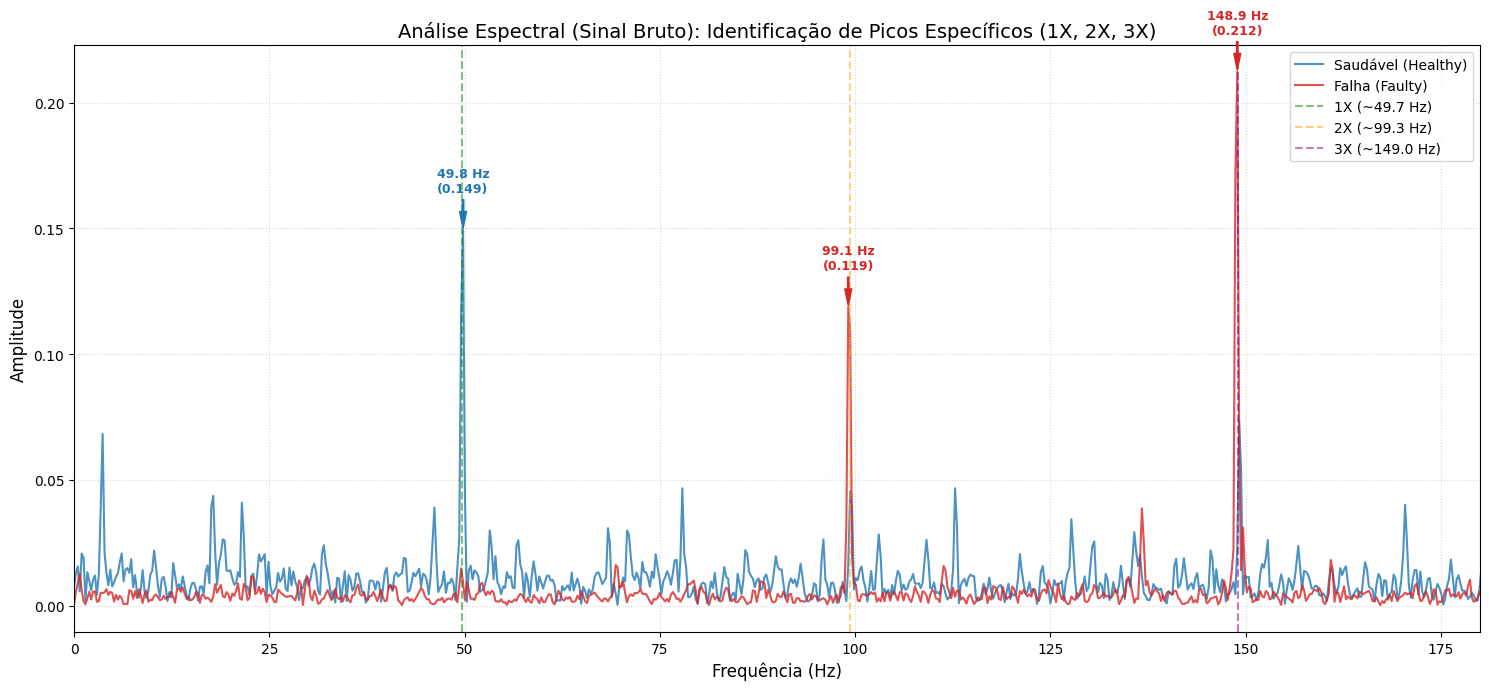

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import fft, fftfreq
from scipy.io import loadmat


def gerar_grafico_espectral_artigo_bruto(path_h, path_f, fs=1000, rpm=2980):
  plt.figure(figsize=(15, 7))
  f_rotacao_teorica = rpm / 60  # ~49.67 Hz

  print("=" * 60)
  print("      EXTRAÇÃO DE VALORES: ANÁLISE ESPECTRAL (HARMÔNICAS)")
  print("=" * 60)

  # Dicionário com os intervalos/critérios de busca específicos por condição e harmônica
  # Formato: 'Condição': {1X: (f_min, f_max), 2X: (f_min, f_max), 3X: (f_min, f_max)}
  criterios_busca = {
      "Saudável (Healthy)": {
          1: (49.6, 49.9),  # 1X para Saudável
      },
      "Falha (Faulty)": {
          2: (99.1, 99.4),  # 2X para Falha
          3: (148.9, 149.1),  # 3X para Falha
      },
  }

  for caminho, rotulo, color in [
      (path_h, "Saudável (Healthy)", "#1f77b4"),
      (path_f, "Falha (Faulty)", "#d62728"),
  ]:
    filename = os.path.basename(caminho)

    # 1. Carregar o Sinal Bruto
    mat = loadmat(caminho)
    chave = [k for k in mat.keys() if not k.startswith("__")][0]
    sinal_bruto = mat[chave]
    if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
      sinal_bruto = sinal_bruto.T

    # 2. Resultante Euclidiana Bruta (Magnitude)
    res = np.linalg.norm(sinal_bruto[:, :3], axis=1)

    # 3. Remoção do componente DC (Média)
    sinal_cent = res - np.mean(res)

    # 4. Cálculo da FFT com janela Hanning
    N = 4096
    yf = fft(sinal_cent[:N] * np.hanning(N))
    xf = fftfreq(N, 1 / fs)

    amplitude = 2.0 / N * np.abs(yf[: N // 2])
    frequencias = xf[: N // 2]

    # --- BUSCA DE PICOS NOS INTERVALOS ESPECIFICADOS ---
    print(f"CONDIÇÃO: {rotulo} ({filename})")

    # Verifica se a condição atual possui regras de busca cadastradas
    if rotulo in criterios_busca:
      for h, (f_min, f_max) in criterios_busca[rotulo].items():
        # Aplica a máscara no intervalo exato informado
        mask = (frequencias >= f_min) & (frequencias <= f_max)

        if np.any(mask):
          amp_pico = np.max(amplitude[mask])
          freq_pico = frequencias[mask][np.argmax(amplitude[mask])]

          print(
              f"-> Harmônica {h}X [{f_min}-{f_max} Hz]: Maior Pico em"
              f" {freq_pico:.2f} Hz | Amplitude: {amp_pico:.4f}"
          )

          # Plota a seta e a anotação do pico no gráfico
          plt.annotate(
              f"{freq_pico:.1f} Hz\n({amp_pico:.3f})",
              xy=(freq_pico, amp_pico),
              xytext=(freq_pico, amp_pico + 0.015),
              arrowprops=dict(
                  facecolor=color, edgecolor=color, shrink=0.05, width=1, headwidth=5
              ),
              ha="center",
              fontsize=9,
              fontweight="bold",
              color=color,
          )

    print("-" * 60)

    plt.plot(
        frequencias, amplitude, label=rotulo, color=color, lw=1.5, alpha=0.8
    )

  # 5. Formatação Estética do Espectro
  plt.title(
      "Análise Espectral (Sinal Bruto): Identificação de Picos Específicos (1X,"
      " 2X, 3X)",
      fontsize=14,
  )
  plt.xlabel("Frequência (Hz)", fontsize=12)
  plt.ylabel("Amplitude", fontsize=12)
  plt.xlim(0, 180)

  # Escala do eixo X de 25 em 25 Hz
  plt.xticks(np.arange(0, 181, 25))

  # Marcadores das Harmônicas Teóricas
  plt.axvline(
      f_rotacao_teorica,
      color="green",
      linestyle="--",
      alpha=0.5,
      label=f"1X (~{f_rotacao_teorica:.1f} Hz)",
  )
  plt.axvline(
      2 * f_rotacao_teorica,
      color="orange",
      linestyle="--",
      alpha=0.5,
      label=f"2X (~{2 * f_rotacao_teorica:.1f} Hz)",
  )
  plt.axvline(
      3 * f_rotacao_teorica,
      color="purple",
      linestyle="--",
      alpha=0.5,
      label=f"3X (~{3 * f_rotacao_teorica:.1f} Hz)",
  )

  plt.legend(loc="upper right")
  plt.grid(True, which="both", linestyle=":", alpha=0.5)
  plt.tight_layout()
  plt.show()


# Execução do script
gerar_grafico_espectral_artigo_bruto(healthy_sample, faulty_sample)

# Frequencia média da harmonica 1x por tipo de sinal

In [ ]:
def calcular_frequencia_media_sinal(file_path, fs=1000, freq_range=(0, 200), N=4096):
    """
    Calcula a frequência de pico (maior amplitude) dentro de uma faixa especificada
    para um sinal vibratório triaxial.

    Args:
        file_path (str): Caminho para o arquivo .mat contendo o sinal.
        fs (int): Frequência de amostragem do sinal (Hz).
        freq_range (tuple): Tupla (min_freq, max_freq) para buscar o pico de frequência.
        N (int): Número de pontos para a FFT (geralmente uma potência de 2).

    Returns:
        float: A frequência de pico com a maior amplitude dentro do freq_range.
    """
    # Carregar o sinal
    mat = loadmat(file_path)
    chave = [k for k in mat.keys() if not k.startswith('__')][0]
    sinal_bruto = mat[chave]

    # Garante eixos nas colunas
    if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
        sinal_bruto = sinal_bruto.T

    # Resultante Euclidiana (Magnitude)
    res = np.linalg.norm(sinal_bruto[:, :3], axis=1)

    # Remoção do componente DC
    sinal_cent = res[:N] - np.mean(res[:N])

    # Aplicação da janela Hanning
    sinal_janelado = sinal_cent * np.hanning(N)

    # FFT
    yf = fft(sinal_janelado)
    xf = fftfreq(N, 1/fs)

    # Amplitude e frequências positivas
    amplitude = 2.0 / N * np.abs(yf[:N // 2])
    frequencias = xf[:N // 2]

    # Filtrar para a faixa de frequência desejada
    mask = (frequencias >= freq_range[0]) & (frequencias <= freq_range[1])
    frequencias_filtradas = frequencias[mask]
    amplitude_filtrada = amplitude[mask]

    if len(amplitude_filtrada) > 0:
        # Encontrar a frequência com a maior amplitude na faixa
        idx_max_amplitude = np.argmax(amplitude_filtrada)
        return frequencias_filtradas[idx_max_amplitude]
    else:
        return np.nan # Retorna NaN se não houver frequências na faixa

# Exemplo de uso:
freq_media_saudavel = calcular_frequencia_media_sinal(healthy_sample)
freq_media_falha = calcular_frequencia_media_sinal(faulty_sample)

print(f"Frequência de pico do sinal SAUDÁVEL: {freq_media_saudavel:.2f} Hz")
print(f"Frequência de pico do sinal COM FALHA: {freq_media_falha:.2f} Hz")

Frequência de pico do sinal SAUDÁVEL: 49.80 Hz
Frequência de pico do sinal COM FALHA: 148.93 Hz


# Frequencia média da harmonica 1x de todos os sinais

In [ ]:
def get_peak_frequency_for_harmonic(file_path, harmonic_num, fs=1000, rpm=2980, N=4096, search_window_hz=2):
    """
    Calcula a frequência de pico para uma harmônica específica de um sinal vibratório triaxial.

    Args:
        file_path (str): Caminho para o arquivo .mat contendo o sinal.
        harmonic_num (int): O número da harmônica (ex: 1 para 1X, 2 para 2X).
        fs (int): Frequência de amostragem do sinal (Hz).
        rpm (int): Rotação nominal da máquina (RPM).
        N (int): Número de pontos para a FFT (geralmente uma potência de 2).
        search_window_hz (float): Largura da janela de busca em Hz ao redor da frequência teórica.

    Returns:
        float: A frequência de pico com a maior amplitude para a harmônica especificada, ou np.nan se não encontrado.
    """
    # Carregar o sinal
    mat = loadmat(file_path)
    chave = [k for k in mat.keys() if not k.startswith('__')][0]
    sinal_bruto = mat[chave]

    # Garante eixos nas colunas
    if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
        sinal_bruto = sinal_bruto.T

    # Resultante Euclidiana (Magnitude)
    res = np.linalg.norm(sinal_bruto[:, :3], axis=1)

    # Remoção do componente DC
    sinal_cent = res[:N] - np.mean(res[:N])

    # Aplicação da janela Hanning
    sinal_janelado = sinal_cent * np.hanning(N)

    # FFT
    yf = fft(sinal_janelado)
    xf = fftfreq(N, 1/fs)

    # Amplitude e frequências positivas
    amplitude = 2.0 / N * np.abs(yf[:N // 2])
    frequencias = xf[:N // 2]

    f_rotacao_teorica = rpm / 60

    f_alvo = harmonic_num * f_rotacao_teorica
    mask = (frequencias >= f_alvo - search_window_hz) & \
           (frequencias <= f_alvo + search_window_hz)

    if np.any(mask):
        idx_max_amplitude = np.argmax(amplitude[mask])
        return frequencias[mask][idx_max_amplitude]
    else:
        return np.nan

# Lista para armazenar todas as frequências de pico da 1ª harmônica
all_1x_peak_frequencies = []

# Processar arquivos Saudáveis
healthy_files = sorted([f for f in os.listdir(healthy_dir) if f.endswith('.mat')])
for h_file in healthy_files:
    file_path = os.path.join(healthy_dir, h_file)
    freq_1x = get_peak_frequency_for_harmonic(file_path, harmonic_num=1)
    if not np.isnan(freq_1x):
        all_1x_peak_frequencies.append(freq_1x)

# Processar arquivos com Falha
faulty_files = sorted([f for f in os.listdir(faulty_dir) if f.endswith('.mat')])
for f_file in faulty_files:
    file_path = os.path.join(faulty_dir, f_file)
    freq_1x = get_peak_frequency_for_harmonic(file_path, harmonic_num=1)
    if not np.isnan(freq_1x):
        all_1x_peak_frequencies.append(freq_1x)

# Calcular a média
if len(all_1x_peak_frequencies) > 0:
    average_1x_frequency = np.mean(all_1x_peak_frequencies)
    print("=" * 70)
    print(f"Frequência média geral da primeira harmônica (1X): {average_1x_frequency:.2f} Hz")
    print("=" * 70)
else:
    print("Nenhuma frequência de pico da primeira harmônica (1X) foi encontrada.")

Frequência média geral da primeira harmônica (1X): 49.71 Hz


# Espectro das Frequência

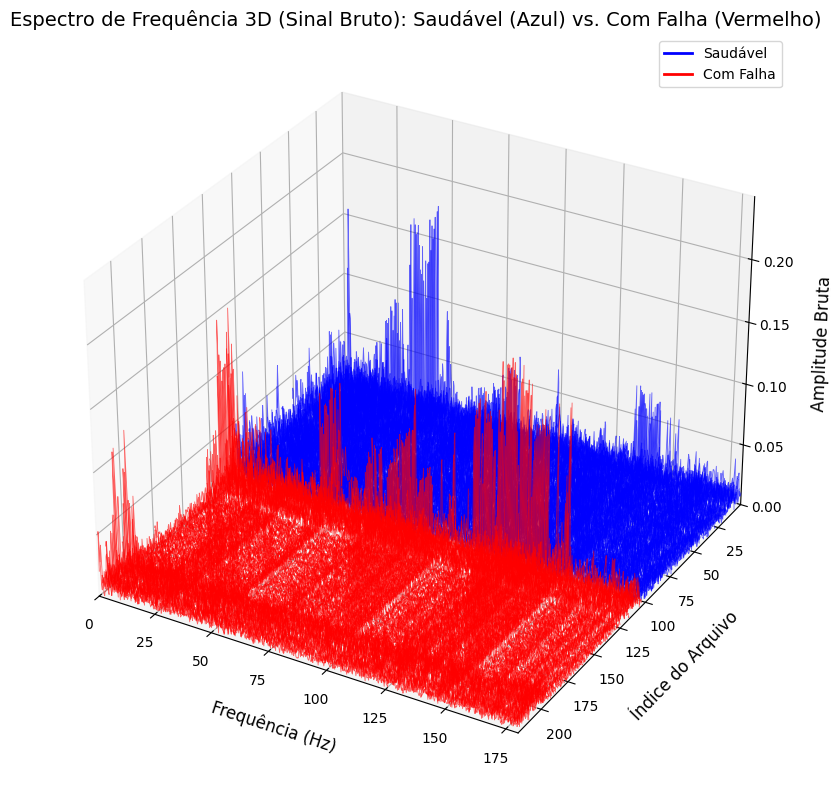

In [ ]:
import os
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from scipy.fft import fft, fftfreq
from scipy.io import loadmat


def extrair_espectro_bruto(file_path, fs=1000, N=4096, f_max=180):
  """Lê o arquivo .mat, calcula a norma euclidiana e retorna o espectro até f_max."""
  mat = loadmat(file_path)
  chave = [k for k in mat.keys() if not k.startswith("__")][0]
  sinal_bruto = mat[chave]

  # Transpõe se os eixos estiverem nas linhas
  if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
    sinal_bruto = sinal_bruto.T

  # 1. Resultante Euclidiana (Magnitude)
  res = np.linalg.norm(sinal_bruto[:, :3], axis=1)

  # 2. Remoção do offset DC (sem aplicar Z-score)
  sinal_cent = res - np.mean(res)

  # 3. FFT com Janela de Hanning
  yf = fft(sinal_cent[:N] * np.hanning(N))
  xf = fftfreq(N, 1 / fs)

  amplitude = 2.0 / N * np.abs(yf[: N // 2])
  frequencias = xf[: N // 2]

  # Filtragem até f_max (180 Hz)
  mask = frequencias <= f_max
  return frequencias[mask], amplitude[mask]


def plot_3d_frequency_spectrum_all_files(base_path, fs=1000, max_files=219):
  fig = plt.figure(figsize=(15, 8))
  ax = fig.add_subplot(111, projection="3d")

  lines = []
  colors = []
  file_counter = 1

  # Mapeamento de pastas e cores
  classes_config = [("Healthy", "Saudável", "blue"), ("Faulty", "Com Falha", "red")]

  for sub_dir, rotulo, cor in classes_config:
    dir_path = os.path.join(base_path, sub_dir)
    if not os.path.exists(dir_path):
      continue

    arquivos = sorted([f for f in os.listdir(dir_path) if f.endswith(".mat")])[
        :max_files
    ]

    for arq in arquivos:
      file_path = os.path.join(dir_path, arq)
      freqs, amps = extrair_espectro_bruto(file_path, fs=fs)

      # Criar os pontos 3D (X: Frequência, Y: Índice do Arquivo, Z: Amplitude)
      y_indices = np.full_like(freqs, file_counter)
      segmento = np.column_stack([freqs, y_indices, amps])

      lines.append(segmento)
      colors.append(cor)
      file_counter += 1

  # Renderização Otimizada via Line3DCollection
  line_collection = Line3DCollection(
      lines, colors=colors, alpha=0.6, linewidths=0.6
  )
  ax.add_collection3d(line_collection)

  # Ajuste manual das fronteiras para a coleção 3D
  all_amps = np.concatenate([line[:, 2] for line in lines])
  max_amp = np.max(all_amps) if len(all_amps) > 0 else 1.0

  ax.set_xlim(0, 180)
  ax.set_ylim(1, file_counter)
  ax.set_zlim(0, max_amp * 1.1)

  # Inverte o eixo Y para posicionar 'Saudável' ao fundo e 'Com Falha' à frente
  ax.invert_yaxis()

  # Escala do eixo X (Frequência) de 25 em 25 Hz (0, 25, 50, ..., 175)
  ax.set_xticks(np.arange(0, 181, 25))

  # Formatação Estética
  ax.set_xlabel("Frequência (Hz)", fontsize=12, labelpad=12)
  ax.set_ylabel("Índice do Arquivo", fontsize=12, labelpad=12)
  ax.set_zlabel("Amplitude Bruta", fontsize=12, labelpad=12)
  plt.title(
      "Espectro de Frequência 3D (Sinal Bruto): Saudável (Azul) vs. Com Falha"
      " (Vermelho)",
      fontsize=14,
  )

  # Legenda Personalizada
  legend_elements = [
      Line2D([0], [0], color="blue", lw=2, label="Saudável"),
      Line2D([0], [0], color="red", lw=2, label="Com Falha"),
  ]
  ax.legend(handles=legend_elements, loc="upper right")

  plt.tight_layout()
  plt.show()


# Exemplo de chamada:
plot_3d_frequency_spectrum_all_files(path)

# Extração dos Atributos

## Domínio do Tempo:
### * RMS (Root Mean Square):
### * Curtose:
### * Fator de Crista:

## Domínio da Frequência (FFT):
### * Amplitudes Harmônicas (1X, 2X e 3X):


In [ ]:
from scipy.stats import kurtosis  # Mais rápido que pandas.Series

def extrair_features(sinal, fs=1000, rpm=2980, N=4096):
    """
    Extrai características estatísticas e espectrais a partir da resultante bruta.
    """
    features = {}
    f_rotacao = rpm / 60.0  # Fundamental (1X) ~49.67 Hz

    # --- Domínio do Tempo (Indicadores Estatísticos de Energia e Impacto) ---
    rms = np.sqrt(np.mean(sinal**2))
    features['rms'] = rms
    features['curtose'] = kurtosis(sinal)  # Fisher kurtosis (normal = 0)
    features['fator_crista'] = np.max(np.abs(sinal)) / rms if rms > 0 else 0

    # --- Domínio da Frequência (FFT) ---
    # 1. Remoção do componente DC (Média) antes de janelar
    sinal_cent = sinal[:N] - np.mean(sinal[:N])

    # 2. Janelamento de Hanning com correção de amplitude
    janela = np.hanning(len(sinal_cent))
    sinal_janelado = sinal_cent * janela

    yf = fft(sinal_janelado)
    xf = fftfreq(len(sinal_cent), 1/fs)

    # Factor de correção de amplitude para a Janela Hanning: 2 / sum(janela)
    amplitude = (2.0 / np.sum(janela)) * np.abs(yf[:N//2])
    frequencias = xf[:N//2]

    # --- Busca de Amplitudes nas Harmônicas (1X, 2X, 3X) ---
    for h in [1, 2, 3]:
        f_alvo = h * f_rotacao
        # Janela de tolerância +/- 3Hz ao redor da frequência teórica
        idx = np.where((frequencias >= f_alvo - 3) & (frequencias <= f_alvo + 3))[0]
        features[f'amp_{h}x'] = np.max(amplitude[idx]) if len(idx) > 0 else 0.0

    return features

# --- Reprocessamento Global e Estruturação do Dataset ---
dados_finais = []

for classe in ['Healthy', 'Faulty']:
    pasta = os.path.join(path, classe)
    if not os.path.exists(pasta):
        continue

    arquivos = [f for f in os.listdir(pasta) if f.endswith('.mat')]

    for arq in arquivos:
        mat = loadmat(os.path.join(pasta, arq))
        chave = [k for k in mat.keys() if not k.startswith('__')][0]
        sinal_bruto = mat[chave]

        # Garante eixos nas colunas
        if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
            sinal_bruto = sinal_bruto.T

        # 1. Resultante Euclidiana BRUTA via Norma (Nativa/Vetorizada)
        res = np.linalg.norm(sinal_bruto[:, :3], axis=1)

        # 2. Extração de características no sinal original
        feat = extrair_features(res, fs=1000, rpm=2980)

        # Target: 0 = Healthy, 1 = Faulty
        feat['target'] = 0 if classe == 'Healthy' else 1
        dados_finais.append(feat)

# 3. Construção do DataFrame Consolidado
df_bruto = pd.DataFrame(dados_finais)

print("\n" + "="*50)
print(f"DATASET PROCESSADO: {len(df_bruto)} AMOSTRAS")
print("="*50)
print(df_bruto.describe().round(4))




DATASET PROCESSADO: 220 AMOSTRAS
            rms   curtose  fator_crista    amp_1x    amp_2x    amp_3x  \
count  220.0000  220.0000      220.0000  220.0000  220.0000  220.0000   
mean     1.7275    0.3132        2.3863    0.1406    0.1364    0.1911   
std      0.1162    0.8955        0.5423    0.1042    0.0781    0.1280   
min      1.4806   -0.4450        1.6919    0.0189    0.0276    0.0244   
25%      1.6919   -0.2006        1.7825    0.0454    0.0677    0.0805   
50%      1.7302   -0.0032        2.4492    0.1107    0.1162    0.1529   
75%      1.7503    0.3780        2.6812    0.2124    0.1997    0.3007   
max      2.7401    5.3385        5.0584    0.3884    0.3149    0.4532   

         target  
count  220.0000  
mean     0.5318  
std      0.5001  
min      0.0000  
25%      0.0000  
50%      1.0000  
75%      1.0000  
max      1.0000  


# Distribuição Espacial dos Atributos - Frequencias Harmônicas

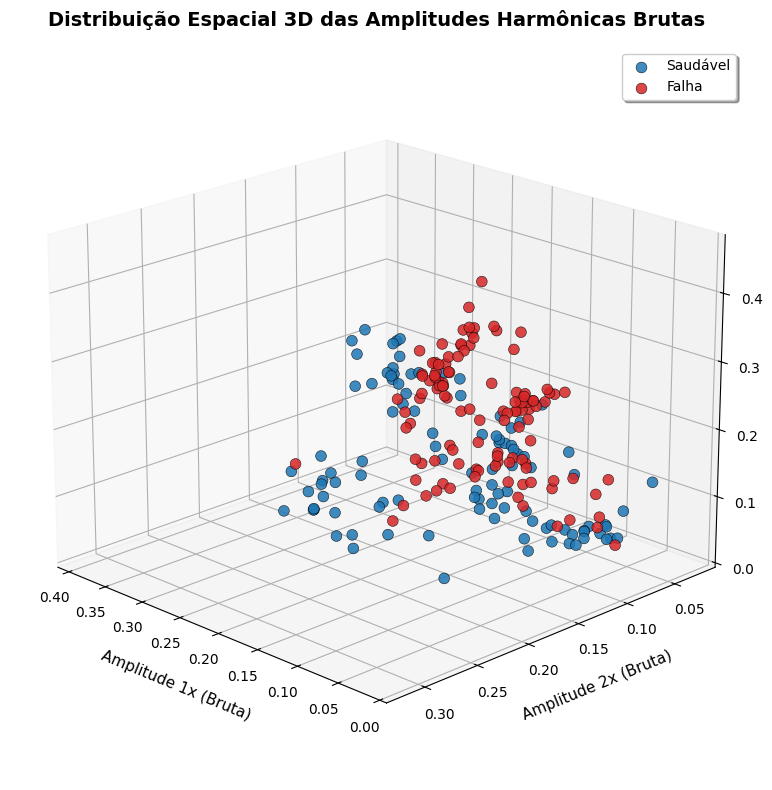

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plotar_grafico_3d_features_harmonicas_brutas(df):
    # 1. Extração dos atributos harmônicos brutos (Eixos: X = 1x, Y = 2x, Z = 3x)
    X = df[['amp_1x', 'amp_2x', 'amp_3x']].values
    y = df['target'].values

    # 2. Paleta Acadêmica (Azul para Saudável, Vermelho para Falha)
    cmap_bold = ['#1f77b4', '#d62728']

    # Configuração padronizada da figura (12x8 polegadas)
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')

    # 3. Plotagem dos pontos
    for i, condicao in enumerate(['Saudável', 'Falha']):
        indices = y == i
        ax.scatter(
            X[indices, 0], X[indices, 1], X[indices, 2],
            c=cmap_bold[i],
            edgecolor='k',
            linewidth=0.4,
            s=60,
            label=condicao,
            alpha=0.85
        )

    # 4. Rótulos (Valores Brutos) e Título
    ax.set_xlabel('Amplitude 1x (Bruta)', fontsize=11, labelpad=10)
    ax.set_ylabel('Amplitude 2x (Bruta)', fontsize=11, labelpad=10)
    ax.set_zlabel('Amplitude 3x (Bruta)', fontsize=11, labelpad=10)

    ax.set_title('Distribuição Espacial 3D das Amplitudes Harmônicas Brutas', fontsize=14, fontweight='bold', pad=15)
    ax.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.5)

    # Ângulo de visão padronizado
    ax.view_init(elev=20, azim=135)

    plt.tight_layout()
    plt.show()

# ==============================================================================
# EXECUÇÃO DIRETA COM df_bruto
# ==============================================================================
plotar_grafico_3d_features_harmonicas_brutas(df_bruto)

# Distribuição Espacial dos Atributos - Estatisticas Temporais

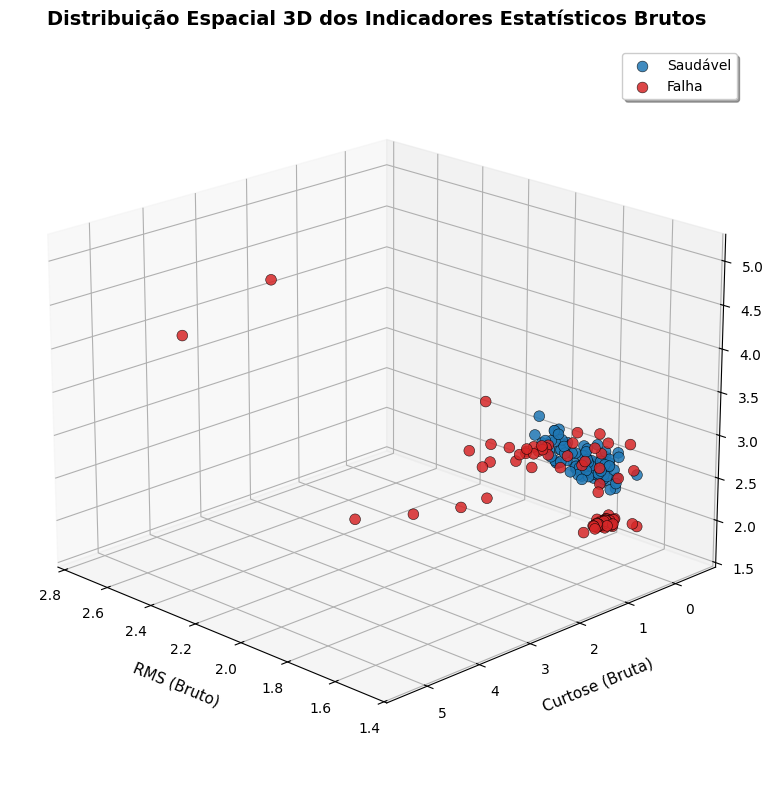

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plotar_grafico_3d_features_estatisticas_brutas(df):
    # 1. Extração dos atributos estatísticos brutos (Eixos: X = RMS, Y = Curtose, Z = Fator Crista)
    X = df[['rms', 'curtose', 'fator_crista']].values
    y = df['target'].values

    # 2. Paleta Acadêmica (Azul para Saudável, Vermelho para Falha)
    cmap_bold = ['#1f77b4', '#d62728']

    # Configuração padronizada da figura (12x8 polegadas)
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')

    # 3. Plotagem dos pontos
    for i, condicao in enumerate(['Saudável', 'Falha']):
        indices = y == i
        ax.scatter(
            X[indices, 0], X[indices, 1], X[indices, 2],
            c=cmap_bold[i],
            edgecolor='k',
            linewidth=0.4,
            s=60,
            label=condicao,
            alpha=0.85
        )

    # 4. Rótulos (Valores Brutos) e Título
    ax.set_xlabel('RMS (Bruto)', fontsize=11, labelpad=10)
    ax.set_ylabel('Curtose (Bruta)', fontsize=11, labelpad=10)
    ax.set_zlabel('Fator de Crista (Bruto)', fontsize=11, labelpad=10)

    ax.set_title('Distribuição Espacial 3D dos Indicadores Estatísticos Brutos', fontsize=14, fontweight='bold', pad=15)
    ax.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.5)

    # Ângulo de visão padronizado
    ax.view_init(elev=20, azim=135)

    plt.tight_layout()
    plt.show()

# ==============================================================================
# EXECUÇÃO DIRETA COM df_bruto
# ==============================================================================
plotar_grafico_3d_features_estatisticas_brutas(df_bruto)

# Estudo dos “Outliers”


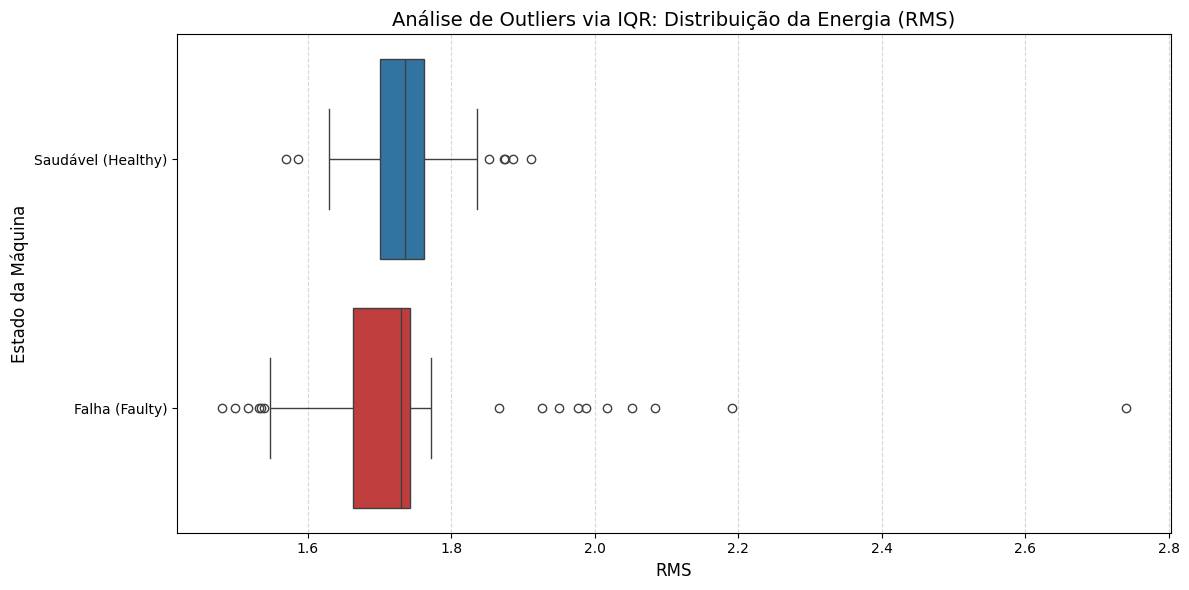

        EXTRAÇÃO DE QUARTIS E LIMITES ESTATÍSTICOS (IQR)
Classe: Saudável (Healthy)
  Q1 (25%): 1.7004 | Mediana (50%): 1.7346 | Q3 (75%): 1.7610
  IQR: 0.0606
  Limites [Inf, Sup]: [1.6095, 1.8520]
  Outliers identificados: 7 de 103 amostras
------------------------------------------------------------
Classe: Falha (Faulty)
  Q1 (25%): 1.6634 | Mediana (50%): 1.7298 | Q3 (75%): 1.7421
  IQR: 0.0787
  Limites [Inf, Sup]: [1.5453, 1.8602]
  Outliers identificados: 16 de 117 amostras
------------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def analise_investigativa_outliers_horizontal(df):
    # --- CONFIGURAÇÃO GRÁFICA DO BOXPLOT HORIZONTAL ---
    plt.figure(figsize=(12, 6))

    # Mapeamento de cores
    cores = {0: '#1f77b4', 1: '#d62728'}

    # Renderização do Boxplot (hue adicionado para evitar avisos de depreciação do Seaborn)
    sns.boxplot(
        x='rms',
        y='target',
        hue='target',
        data=df,
        orient='h',
        palette=cores,
        legend=False
    )

    # Rótulos do eixo Y
    plt.yticks([0, 1], ['Saudável (Healthy)', 'Falha (Faulty)'])

    plt.title("Análise de Outliers via IQR: Distribuição da Energia (RMS)", fontsize=14)
    plt.xlabel("RMS", fontsize=12)
    plt.ylabel("Estado da Máquina", fontsize=12)

    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # --- CÁLCULO E EXTRAÇÃO DOS LIMITES ESTATÍSTICOS (MÉTODO IQR) ---
    print("=" * 60)
    print("        EXTRAÇÃO DE QUARTIS E LIMITES ESTATÍSTICOS (IQR)")
    print("=" * 60)

    for t in [0, 1]:
        label = 'Falha (Faulty)' if t == 1 else 'Saudável (Healthy)'
        dados = df[df['target'] == t]['rms']

        q1 = dados.quantile(0.25)
        q3 = dados.quantile(0.75)
        iqr = q3 - q1

        limite_inferior = max(0, q1 - 1.5 * iqr)  # Trunca em 0 pois RMS não é negativo
        limite_superior = q3 + 1.5 * iqr

        # Contagem de outliers identificados pelo método
        outliers_qtd = ((dados < limite_inferior) | (dados > limite_superior)).sum()

        print(f"Classe: {label}")
        print(f"  Q1 (25%): {q1:.4f} | Mediana (50%): {dados.median():.4f} | Q3 (75%): {q3:.4f}")
        print(f"  IQR: {iqr:.4f}")
        print(f"  Limites [Inf, Sup]: [{limite_inferior:.4f}, {limite_superior:.4f}]")
        print(f"  Outliers identificados: {outliers_qtd} de {len(dados)} amostras")
        print("-" * 60)

# Execução
analise_investigativa_outliers_horizontal(df_bruto)

# Análise gráfica da distribuição estatística com Boxplot dos Atributos




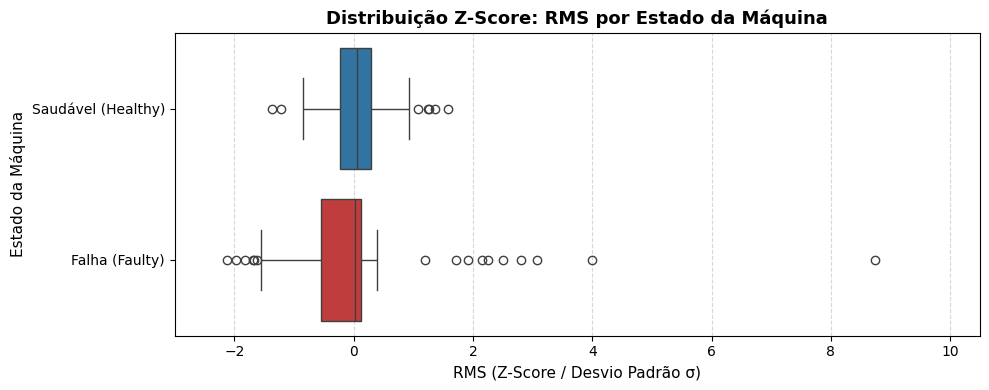

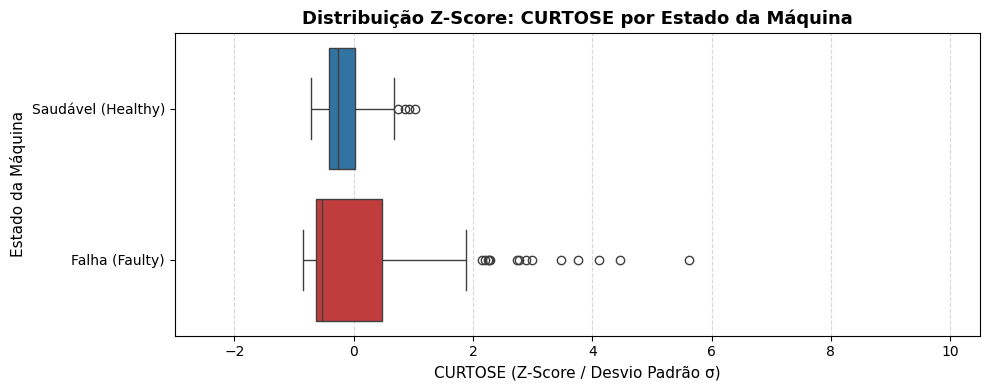

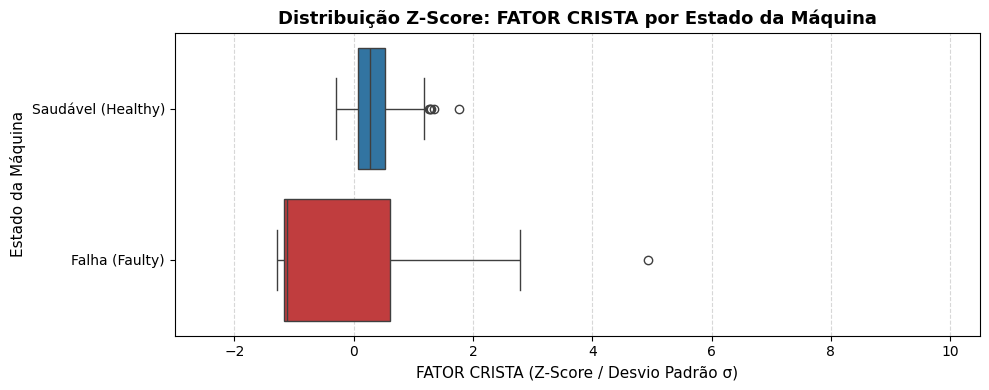

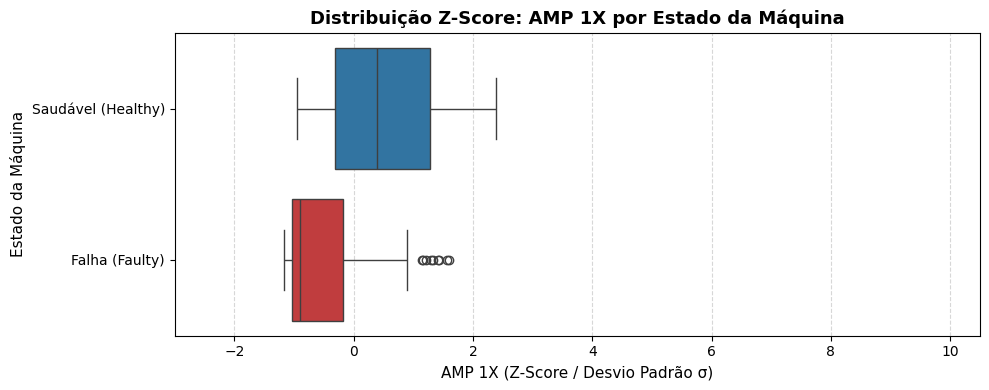

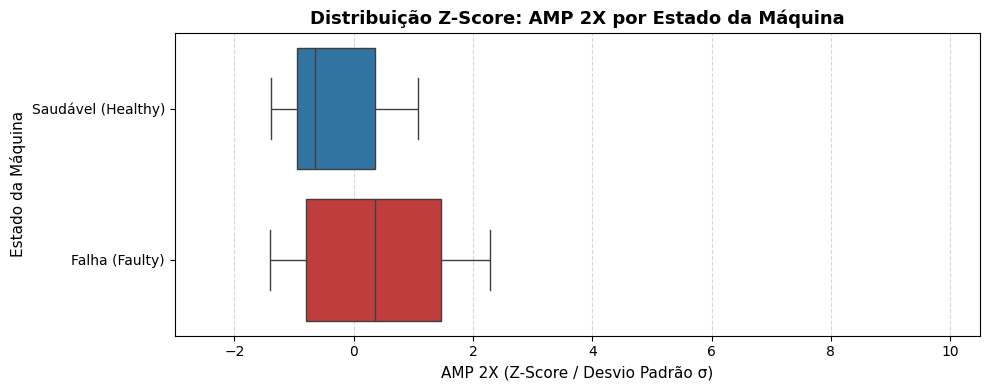

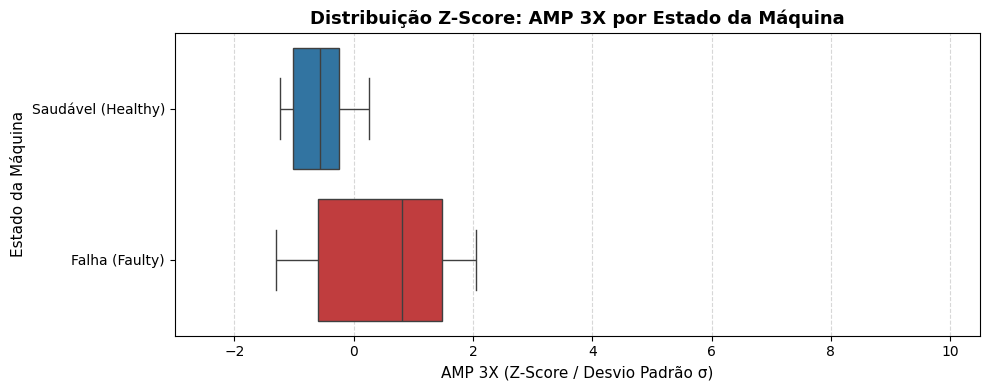

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

def plot_feature_boxplots_zscore(df):
    """
    Gera boxplots horizontais padronizados em Z-Score para comparação
    homogênea da separabilidade das features na etapa de EDA.
    """
    # 1. Isola as features e a variável alvo
    features = [col for col in df.columns if col != 'target']

    # 2. Aplica o Z-Score temporário apenas para a visualização gráfica
    scaler = StandardScaler()
    df_plot = df.copy()
    df_plot[features] = scaler.fit_transform(df_plot[features])

    # Mapeamento cromático e de rótulos
    colors = {0: '#1f77b4', 1: '#d62728'}
    target_labels = {0: 'Saudável (Healthy)', 1: 'Falha (Faulty)'}

    for feature in features:
        fig, ax = plt.subplots(figsize=(10, 4))

        # Boxplot horizontal por classe
        sns.boxplot(
            x=feature,
            y='target',
            hue='target',
            data=df_plot,
            orient='h',
            palette=colors,
            ax=ax,
            legend=False
        )

        # 3. Eixo X padronizado globalmente em desvios padrões (σ)
        ax.set_xlim(-3, 10.5)

        # Ajuste de títulos e rótulos do eixo
        nome_formatado = feature.replace('_', ' ').upper()
        ax.set_title(f'Distribuição Z-Score: {nome_formatado} por Estado da Máquina', fontsize=13, fontweight='bold')
        ax.set_xlabel(f'{nome_formatado} (Z-Score / Desvio Padrão σ)', fontsize=11)
        ax.set_ylabel('Estado da Máquina', fontsize=11)

        # Ajuste dos rótulos do eixo Y (Classes)
        ax.set_yticks([0, 1])
        ax.set_yticklabels([target_labels[0], target_labels[1]])

        # Grade pontilhada para facilitar a leitura visual
        ax.grid(axis='x', linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.show()

# Chamada da função (o df_bruto original permanece intocado no script)
plot_feature_boxplots_zscore(df_bruto)

# Análise Estatística da Função Densidade de Probabilidade (PDF)


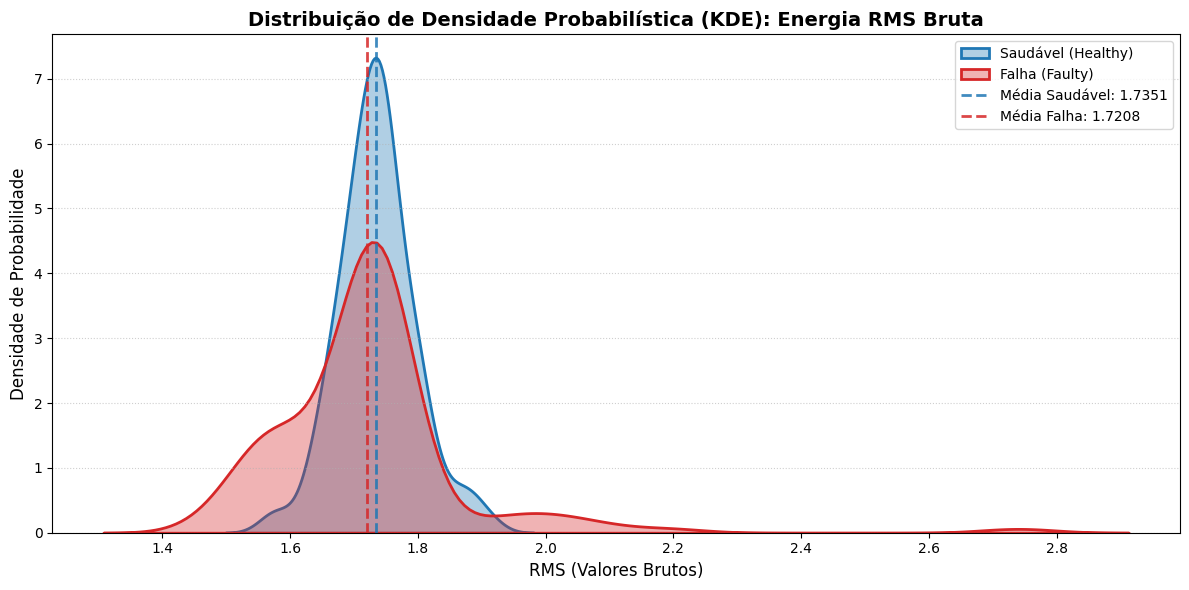

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plotar_distribuicao_rms_estatistica(df):
    plt.figure(figsize=(12, 6))

    # Mapeamento cromático e de rótulos
    cores = {0: '#1f77b4', 1: '#d62728'}
    labels = {0: 'Saudável (Healthy)', 1: 'Falha (Faulty)'}

    # 1. Plotagem das curvas de densidade (KDE) com normalização independente
    for target, cor in cores.items():
        dados_classe = df[df['target'] == target]['rms']

        sns.kdeplot(
            data=dados_classe,
            fill=True,
            color=cor,
            label=labels[target],
            alpha=0.35,
            linewidth=2,
            common_norm=False # Garante a independência de escala de densidade
        )

    # 2. Adição de linhas verticais tracejadas para destacar as médias
    for target, cor in cores.items():
        media_rms = df[df['target'] == target]['rms'].mean()

        plt.axvline(
            x=media_rms,
            color=cor,
            linestyle='--',
            linewidth=2,
            alpha=0.85,
            label=f'Média {labels[target].split()[0]}: {media_rms:.4f}'
        )

    plt.title("Distribuição de Densidade Probabilística (KDE): Energia RMS Bruta", fontsize=14, fontweight='bold')
    plt.xlabel("RMS (Valores Brutos)", fontsize=12)
    plt.ylabel("Densidade de Probabilidade", fontsize=12)

    plt.legend(fontsize=10, loc='upper right')
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

# EXECUÇÃO COM DADOS BRUTOS (Corrigido)
plotar_distribuicao_rms_estatistica(df_bruto)

# Calculo estatistico do RMS

In [ ]:
import pandas as pd
from scipy.stats import kurtosis

def analisar_estatisticas_rms(df):
    resultados = []

    for target_val, label in zip([0, 1], ['Saudável (Healthy)', 'Falha (Faulty)']):
        subset = df[df['target'] == target_val]['rms']

        media = subset.mean()
        desvio_padrao = subset.std()
        pico_max = subset.max()
        pico_min = subset.min()
        amplitude = pico_max - pico_min

        # Curtose de Fisher (Normal = 0.0). Para Curtose Pearson (Normal = 3.0), use fisher=False
        curtose_val = kurtosis(subset, fisher=True)

        resultados.append({
            'Estado': label,
            'Média': media,
            'Desvio Padrão': desvio_padrao,
            'Mínimo': pico_min,
            'Máximo': pico_max,
            'Amplitude (P-P)': amplitude,
            'Curtose (Fisher)': curtose_val
        })

    df_resultados = pd.DataFrame(resultados)

    print("\n" + "="*80)
    print("           ANÁLISE ESTATÍSTICA DESCRITIVA DA ENERGIA (RMS BRUTO)")
    print("="*80)
    # Formatação com precisão de 4 casas decimais para leitura clara das magnitudes
    print(df_resultados.to_string(index=False, float_format=lambda x: f'{x:12.4f}'))
    print("="*80)

# CHAMADA CORRIGIDA: Utilizando o DataFrame de dados brutos
analisar_estatisticas_rms(df_bruto)


           ANÁLISE ESTATÍSTICA DESCRITIVA DA ENERGIA (RMS BRUTO)
            Estado        Média  Desvio Padrão       Mínimo       Máximo  Amplitude (P-P)  Curtose (Fisher)
Saudável (Healthy)       1.7351         0.0593       1.5692       1.9113           0.3421            0.8227
    Falha (Faulty)       1.7208         0.1493       1.4806       2.7401           1.2595           17.9942


# Análise Comparativa das Densidades de Probabilidade dos Atributos


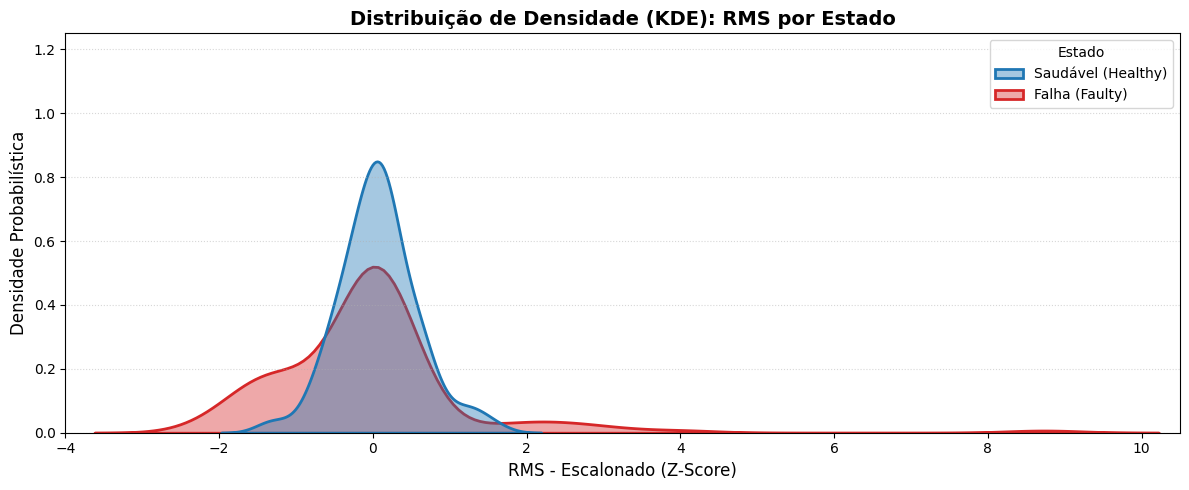

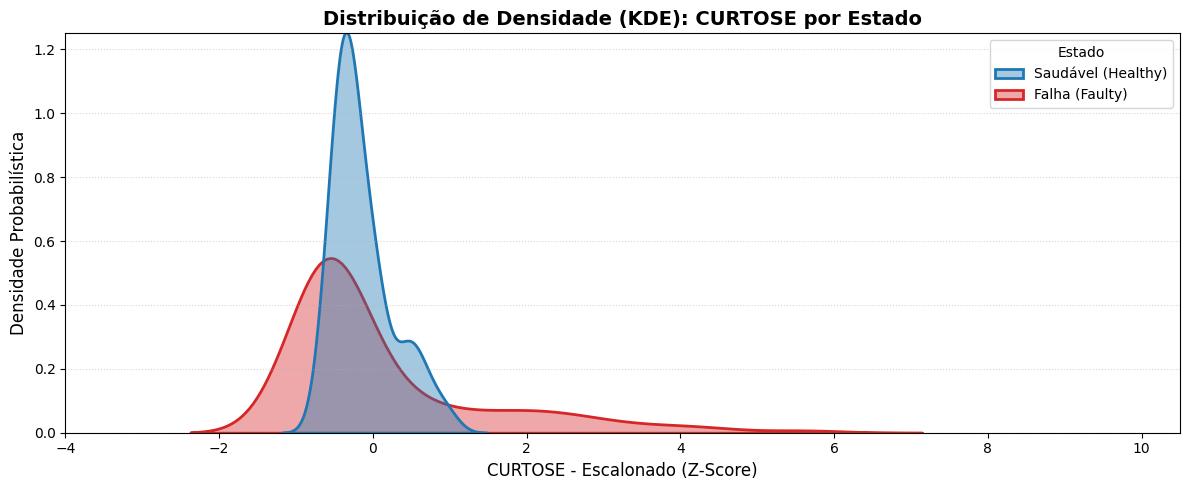

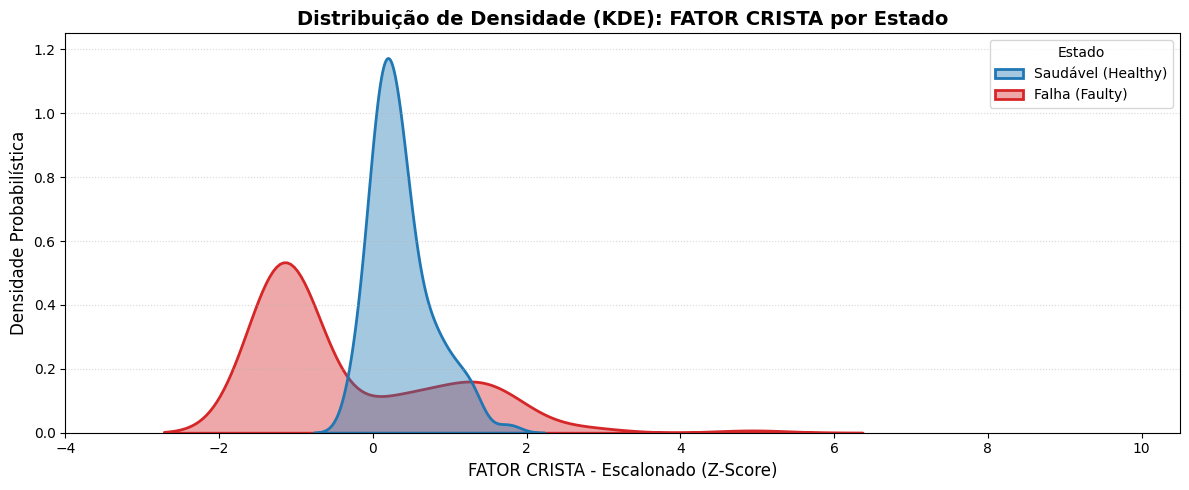

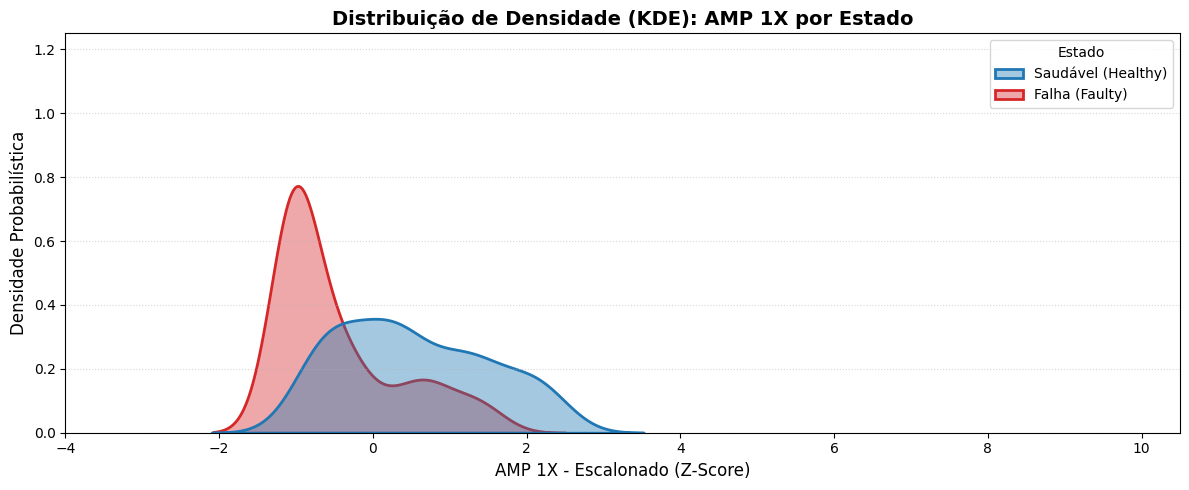

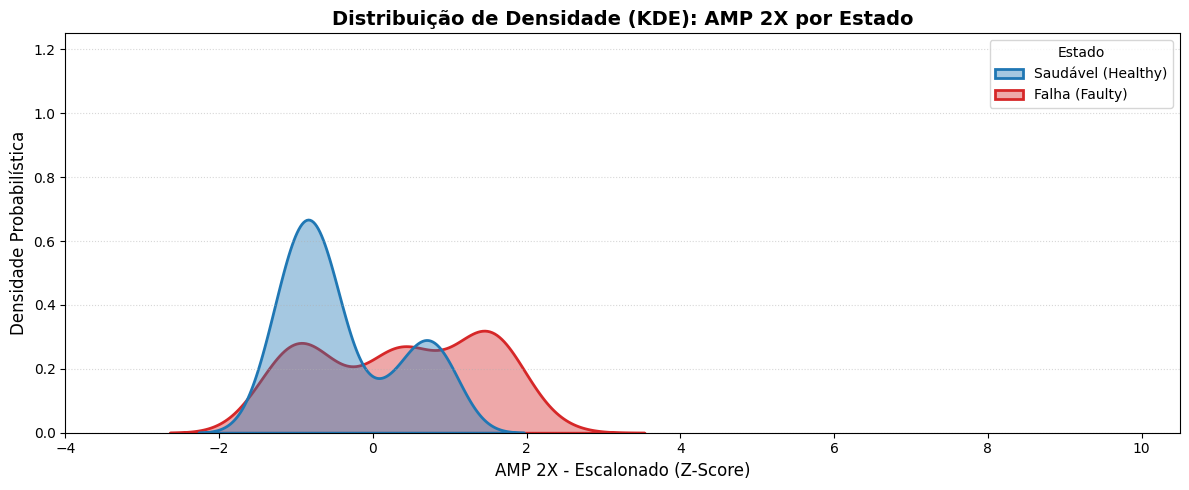

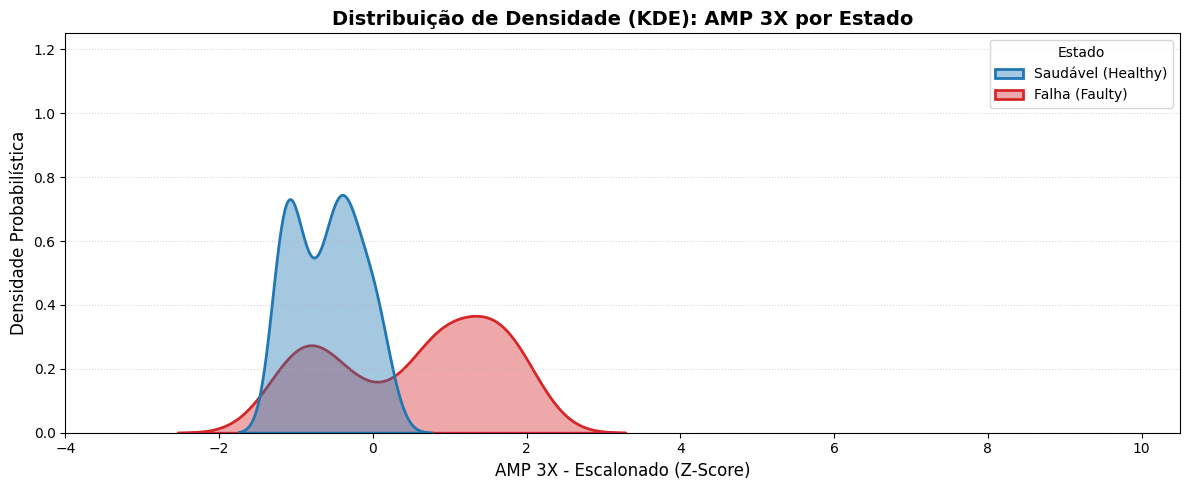

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

def plot_feature_kde_comparisons_zscore(df, xlim_global=(-4, 10.5), ylim_global=(0, 1.25)):
    """
    Gera curvas de densidade de probabilidade (KDE/PDF) padronizadas em Z-Score
    para comparar a separabilidade dos atributos em uma mesma régua gráfica.
    """
    # 1. Obtém todas as colunas de características (ignorando 'target')
    features = [col for col in df.columns if col != 'target']

    # 2. Aplica o Z-Score temporário apenas para a visualização gráfica
    scaler = StandardScaler()
    df_plot = df.copy()
    df_plot[features] = scaler.fit_transform(df_plot[features])

    # Paleta de cores e rótulos
    colors = {0: '#1f77b4', 1: '#d62728'}
    target_labels = {0: 'Saudável (Healthy)', 1: 'Falha (Faulty)'}

    # ==============================================================================
    # RENDERIZAÇÃO DOS GRÁFICOS KDE EM ESCALA Z-SCORE
    # ==============================================================================
    for feature in features:
        fig, ax = plt.subplots(figsize=(12, 5))

        # Plotagem do KDE com os dados padronizados
        sns.kdeplot(
            data=df_plot,
            x=feature,
            hue='target',
            fill=True,
            common_norm=False,
            palette=colors,
            ax=ax,
            alpha=0.4,
            linewidth=2
        )

        # Formatação de Título e Rótulos
        nome_formatado = feature.replace("_", " ").upper()
        ax.set_title(f'Distribuição de Densidade (KDE): {nome_formatado} por Estado', fontsize=14, fontweight='bold')
        ax.set_xlabel(f'{nome_formatado} - Escalonado (Z-Score)', fontsize=12)
        ax.set_ylabel('Densidade Probabilística', fontsize=12)

        # Legenda padronizada
        handles = ax.get_legend().legend_handles if ax.get_legend() else []
        ax.legend(handles=handles, title='Estado', labels=[target_labels[0], target_labels[1]])

        # Aplicação dos limites estandardizados para Z-Score (idênticos à Figura 10)
        ax.set_xlim(xlim_global)
        ax.set_ylim(ylim_global)

        ax.grid(axis='y', linestyle=':', alpha=0.5)
        plt.tight_layout()
        plt.show()

# EXECUÇÃO COM OS DADOS BRUTOS (escalonamento isolado internamente na função)
plot_feature_kde_comparisons_zscore(df_bruto)

# Análise de Correlação dos Atributos de Vibração


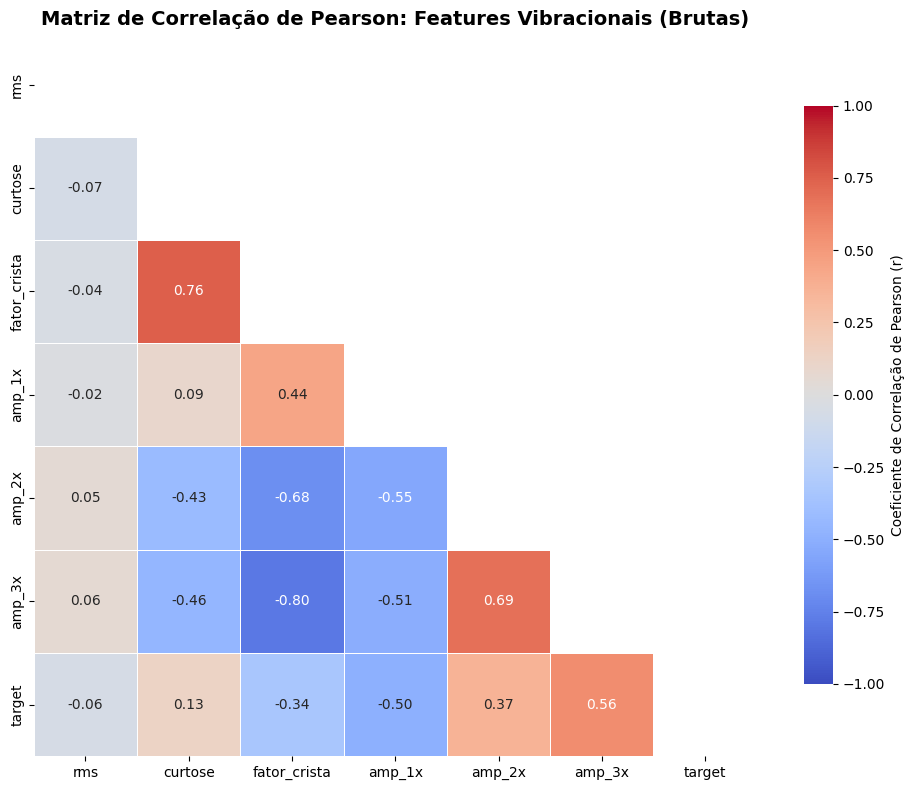

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- 1. CÁLCULO DA MATRIZ DE CORRELAÇÃO DE PEARSON (DADOS BRUTOS) ---
# Calcula a correlação linear sobre o DataFrame de dados brutos
corr = df_bruto.corr()

# Mascaramento da metade superior (opcional, deixa o mapa visualmente mais limpo)
mask = np.triu(np.ones_like(corr, dtype=bool))

# --- 2. CONFIGURAÇÃO E RENDERIZAÇÃO DO HEATMAP ---
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    mask=mask,             # Oculta a metade superior redundante
    annot=True,            # Exibe os coeficientes numéricos em cada célula
    fmt=".2f",             # Arredonda para duas casas decimais
    cmap='coolwarm',       # Escala divergente: azul (negativo), vermelho (positivo)
    center=0,              # Define o centro neutro em r = 0
    vmin=-1, vmax=1,       # Trava os limites absolutos do coeficiente de Pearson [-1, +1]
    square=True,           # Mantém as células quadradas
    linewidths=0.5,        # Linhas de separação entre as células
    cbar_kws={'label': 'Coeficiente de Correlação de Pearson (r)', 'shrink': 0.8}
)

plt.title("Matriz de Correlação de Pearson: Features Vibracionais (Brutas)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlação dos Atributos - Valores

In [ ]:
def analisar_correlacao_target(df):
    # 1. Calcular a matriz de correlação e isolar a série do 'target'
    corr_series = df.corr()['target'].drop('target') # Remove a auto-correlação do target

    # 2. Criar DataFrame descritivo com a Magnitude Absoluta (|r|) para ordenação correta
    df_corr = pd.DataFrame({
        'Feature': corr_series.index,
        'Coeficiente (r)': corr_series.values,
        'Magnitude (|r|)': corr_series.abs().values
    })

    # 3. Ordenar pela magnitude da relação (do maior para o menor impacto)
    df_corr = df_corr.sort_values(by='Magnitude (|r|)', ascending=False).drop(columns=['Magnitude (|r|)'])

    # 4. Formatação de tabela em estilo de publicação acadêmica/relatório
    print("=" * 65)
    print("      RANKING DE CORRELAÇÃO DAS FEATURES COM O ESTADO (TARGET)")
    print("=" * 65)
    print(f"{'Feature':<30} | {'Coeficiente (r)':>15} | {'Direção':>10}")
    print("-" * 65)

    for _, row in df_corr.iterrows():
        feat = row['Feature'].replace("_", " ").upper()
        val = row['Coeficiente (r)']
        direcao = "Positiva" if val > 0 else "Negativa"
        print(f"{feat:<30} | {val:>15.4f} | {direcao:>10}")

    print("=" * 65)

# EXECUÇÃO CORRIGIDA COM DADOS BRUTOS
analisar_correlacao_target(df_bruto)

      RANKING DE CORRELAÇÃO DAS FEATURES COM O ESTADO (TARGET)
Feature                        | Coeficiente (r) |    Direção
-----------------------------------------------------------------
AMP 3X                         |          0.5588 |   Positiva
AMP 1X                         |         -0.4993 |   Negativa
AMP 2X                         |          0.3669 |   Positiva
FATOR CRISTA                   |         -0.3430 |   Negativa
CURTOSE                        |          0.1294 |   Positiva
RMS                            |         -0.0616 |   Negativa


# PARTE 02 - MODELO DE CLASSIFICAÇÃO CLÁSSICO E RESULTADOS

# Pipeline - Divisão de Treino e Teste

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Copia o DataFrame bruto (sem remoções prévias de outliers para evitar Data Leakage)
df_pipeline = df_bruto.copy()

# 2. Semente de aleatoriedade para reprodutibilidade
RANDOM_STATE = 42

# 3. Isola as características preditoras (X) e o rótulo da máquina (y)
X = df_pipeline.drop(columns=['target'])
y = df_pipeline['target']

# 4. Divisão estratificada em conjuntos de Treino (70%) e Teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,             # 30% reservado estritamente para avaliação final
    random_state=RANDOM_STATE,  # Garante reprodutibilidade dos experimentos
    stratify=y                  # Mantém a proporção exata entre sadios e falhas em ambas as fatias
)

# 5. Exibição das dimensões e verificação da distribuição de classes
print(f"Dimensões do Treino (X_train): {X_train.shape}")
print(f"Dimensões do Teste  (X_test) : {X_test.shape}")
print("\nDistribuição das classes no Treino (%):")
print(y_train.value_counts(normalize=True) * 100)

Dimensões do Treino (X_train): (154, 6)
Dimensões do Teste  (X_test) : (66, 6)

Distribuição das classes no Treino (%):
target
1    53.246753
0    46.753247
Name: proportion, dtype: float64


# Pipeline - Remoção de Outliers

In [ ]:
import pandas as pd

def remover_outliers_superiores_sadios(X_tr, y_tr, features, fator_iqr=1.5):
    """
    Identifica e remove APENAS as amostras com valores atípicos SUPERIORES
    na classe sadia (target = 0) do conjunto de treino.

    Preserva 100% dos dados de falha (target = 1) e o conjunto de teste.
    """
    X_clean = X_tr.copy()
    y_clean = y_tr.copy()

    # Isola os índices das amostras sadias no treino
    indices_sadios = y_clean[y_clean == 0].index

    indices_outliers = set()

    for col in features:
        # Calcula os quantis estritamente na classe sadia de treino
        Q1 = X_clean.loc[indices_sadios, col].quantile(0.25)
        Q3 = X_clean.loc[indices_sadios, col].quantile(0.75)
        IQR = Q3 - Q1

        # Limite superior para identificar picos atípicos
        limite_superior = Q3 + (fator_iqr * IQR)

        # Encontra os índices das amostras sadias que superam o limite
        outliers_col = indices_sadios[X_clean.loc[indices_sadios, col] > limite_superior]
        indices_outliers.update(outliers_col)

    # Remove as linhas identificadas
    X_clean = X_clean.drop(index=list(indices_outliers))
    y_clean = y_clean.drop(index=list(indices_outliers))

    print("=" * 60)
    print("      REMOÇÃO DE OUTLIERS SUPERIORES (CLASSE SADIA)")
    print("=" * 60)
    print(f"Amostras sadias removidas : {len(indices_outliers)}")
    print(f"Dimensão final do X_train  : {X_clean.shape}")
    print("=" * 60)

    return X_clean, y_clean

# Lista de atributos numéricos analisados
numeric_features = ['rms', 'curtose', 'fator_crista', 'amp_1x', 'amp_2x', 'amp_3x']

# Execução estritamente no conjunto de Treino
X_train_filtered, y_train_filtered = remover_outliers_superiores_sadios(
    X_train, y_train, features=numeric_features, fator_iqr=1.5
)

      REMOÇÃO DE OUTLIERS SUPERIORES (CLASSE SADIA)
Amostras sadias removidas : 5
Dimensão final do X_train  : (149, 6)


# Pipeline - Transformação de Numéricos e Categóricos


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# 1. Definição explícita da lista de características numéricas
numeric_features = [
    'rms',
    'curtose',
    'fator_crista',
    'amp_1x',
    'amp_2x',
    'amp_3x'
]

# 2. Pipeline de transformação numérico
numeric_transformer = Pipeline([
    # Trata eventuais dados faltantes
    ('imputer', SimpleImputer(strategy='median')),

    # Padronização Z-score (Média 0, Desvio Padrão 1)
    ('scaler', StandardScaler())
])

# 3. Unificador (ColumnTransformer)
# Removemos o bloqueio categórico, já que o dataset contém apenas atributos numéricos
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features)
])


# Pipeline - Validação Cruzada de Modelos Clássicos e Avaliação de Desempenho

In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# 1. Configuração do gerador do K-Fold Estratificado
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Lista com as instâncias dos classificadores a serem testados
modelos = [
    ("Regressão Logística", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("Árvore de Decisão", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE)),
    ("KNN", KNeighborsClassifier()),
    ("SVM", SVC(random_state=RANDOM_STATE))
]

resultados = []

# 3. Laço de avaliação comparativa dos algoritmos
for nome, modelo in modelos:

    # Pipeline unificado (Pré-processador + Modelo)
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", modelo)
    ])

    # Validação Cruzada Estratificada aplicada ESTRITAMENTE sobre o Treino Filtrado
    scores = cross_val_score(
        pipeline,
        X_train_filtered,      # Garante o isolamento do conjunto de teste (Holdout)
        y_train_filtered,      # Rótulos da classe de vibração (0: Sadio, 1: Falha)
        cv=cv_stratified,      # Preserva a proporção das classes em todos os folds
        scoring="accuracy"
    )

    resultados.append({
        "Modelo": nome,
        "Acurácia Média": scores.mean(),
        "Desvio Padrão": scores.std()
    })

# 4. Estruturação e ordenação do relatório comparativo
resultados_df = pd.DataFrame(resultados)
resultados_df["Acurácia Média (%)"] = (resultados_df["Acurácia Média"] * 100).round(2)
resultados_df["Desvio Padrão (%)"] = (resultados_df["Desvio Padrão"] * 100).round(2)

# Exibe ordenado do melhor para o pior desempenho
resultados_df = resultados_df.sort_values(by="Acurácia Média", ascending=False).drop(columns=["Acurácia Média", "Desvio Padrão"])

print("\n" + "="*70)
print("     BENCHMARK DE MODELOS - VALIDAÇÃO CRUZADA (K-FOLD ESTRATIFICADO)")
print("="*70)
print(resultados_df.to_string(index=False))
print("="*70)


     BENCHMARK DE MODELOS - VALIDAÇÃO CRUZADA (K-FOLD ESTRATIFICADO)
             Modelo  Acurácia Média (%)  Desvio Padrão (%)
                SVM               98.67               1.63
                KNN               97.33               2.49
      Random Forest               93.29               4.71
  Árvore de Decisão               93.29               3.65
Regressão Logística               89.29               3.84


# Pipeline - Definição do Classificador e Verificação Inicial do Desempenho

## Entrada: Classificador KNN

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Montagem do Pipeline unificado (Pré-processador + Classificador k-NN)
pipeline_full = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))  # Hiperparâmetro k=5 padrão
])

# 2. Treinamento executado sobre os dados de TREINO JÁ FILTRADOS
pipeline_full.fit(X_train_filtered, y_train_filtered)

# 3. Predição sobre o conjunto de TESTE INTACTO (30% reservado)
y_pred = pipeline_full.predict(X_test)

# 4. Avaliação de Desempenho
print("=" * 60)
print("     AVALIAÇÃO DE DESEMPENHO DO MODELO KNN NO TESTE")
print("=" * 60)
print(f"Acurácia Global: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

print("Relatório de Classificação Detalhado:")
print(classification_report(y_test, y_pred, digits=4, target_names=['Saudável (0)', 'Falha (1)']))
print("=" * 60)

     AVALIAÇÃO DE DESEMPENHO DO MODELO KNN NO TESTE
Acurácia Global: 95.45%

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

Saudável (0)     0.9375    0.9677    0.9524        31
   Falha (1)     0.9706    0.9429    0.9565        35

    accuracy                         0.9545        66
   macro avg     0.9540    0.9553    0.9545        66
weighted avg     0.9550    0.9545    0.9546        66



# Pipeline - Análise de Generalização via Validação Cruzada (K-Fold)

## Entrada: Classificador KNN



In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Configuração da Validação Cruzada Estratificada (5 Folds)
# Mantém a mesma proporção de Saudável/Falha em cada um dos 5 blocos
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Execução da Validação Cruzada ESTRITAMENTE sobre o Treino Filtrado
scores = cross_val_score(
    pipeline_full,           # Pipeline que aplica o StandardScaler e o KNN em cada fold
    X_train_filtered,        # Matriz de treino filtrada (sem o conjunto de teste)
    y_train_filtered,        # Target de treino
    cv=cv_stratified,        # Estratificação garantida
    scoring='accuracy'       # Métrica de acurácia
)

# 3. Montagem do Relatório de Desempenho em DataFrame
data = {
    "Métrica": [f"Fold {i+1}" for i in range(len(scores))] + ["Acurácia Média", "Desvio Padrão"],
    "Valor": [f"{s*100:.2f}%" for s in scores] + [f"{scores.mean()*100:.2f}%", f"{scores.std()*100:.2f}%"]
}

df_cv_report = pd.DataFrame(data)

print("\n" + "="*70)
print("       RELATÓRIO DE VALIDAÇÃO CRUZADA ESTRATIFICADA (K-FOLD TREINO)")
print("="*70)
print(df_cv_report.to_string(index=False))
print("="*70)



       RELATÓRIO DE VALIDAÇÃO CRUZADA ESTRATIFICADA (K-FOLD TREINO)
       Métrica   Valor
        Fold 1  96.67%
        Fold 2 100.00%
        Fold 3  96.67%
        Fold 4  93.33%
        Fold 5 100.00%
Acurácia Média  97.33%
 Desvio Padrão   2.49%


# Pipeline - Otimização de Hiperparâmetros via Busca em Grade (Grid Search)

## Entrada: Classificador KNN


In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Pipeline unificado com o KNN Classifier
pipeline_grid = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])

# 2. Grade de hiperparâmetros para busca exaustiva no KNN
param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 13, 15],  # Quantidade de vizinhos mais próximos
    'model__weights': ['uniform', 'distance'],       # Função de ponderação dos vizinhos
    'model__metric': ['euclidean', 'manhattan']      # Métricas de distância
}

# 3. Configuração da Validação Cruzada Estratificada
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 4. Instância do GridSearchCV com a validação estratificada
grid_search = GridSearchCV(
    estimator=pipeline_grid,
    param_grid=param_grid,
    cv=cv_stratified,         # Garante a proporção exata de classes em cada fold
    scoring='accuracy',       # Métrica de otimização
    n_jobs=-1                 # Uso de multiprocessamento
)

# 5. Ajuste EXCLUSIVO sobre os dados de treino filtrados
grid_search.fit(X_train_filtered, y_train_filtered)

# 6. Exibição e formatação tabular dos resultados
print("\n" + "="*60)
print("     MELHORES HIPERPARÂMETROS ENCONTRADOS PARA O KNN")
print("="*60)

formatted_params = {
    key.replace('model__', ''): [value]
    for key, value in grid_search.best_params_.items()
}
df_best_params = pd.DataFrame(formatted_params).melt(var_name='Parâmetro', value_name='Valor')
print(df_best_params.to_string(index=False))

print("="*60)
print(f"Melhor Acurácia Média no Treino (CV): {grid_search.best_score_ * 100:.2f}%")
print("="*60)


     MELHORES HIPERPARÂMETROS ENCONTRADOS PARA O KNN
  Parâmetro     Valor
     metric euclidean
n_neighbors         5
    weights  distance
Melhor Acurácia Média no Treino (CV): 98.67%


# Pipeline -  Validação do Modelo de Classificação e Matriz de Confusão

## Entrada: Classificador KNN


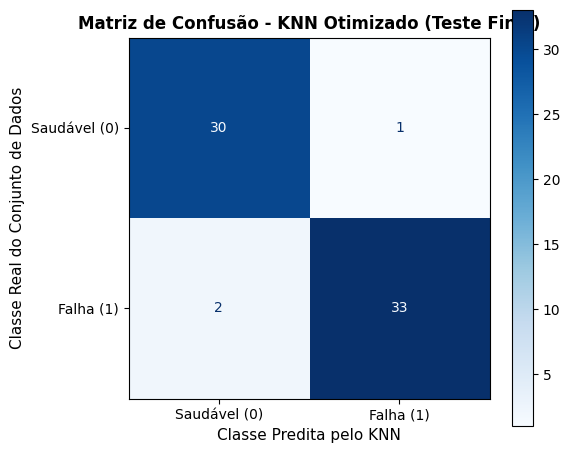


             KNN - DETALHAMENTO DA MATRIZ DE CONFUSÃO
Verdadeiros Negativos (Saudável -> Saudável) : 30
Falsos Positivos      (Saudável -> Falha)    : 1 (Alarmes Falsos)
Verdadeiros Positivos (Falha -> Falha)       : 33
Falsos Negativos      (Falha -> Saudável)    : 2 (Falhas Não Detectadas)
Amostras Totais Avaliadas                    : 66

             MÉTRICAS DE DESEMPENHO - KNN
             Métrica            Valor                                Descrição
Precision (Saudável)           0.9375            Precisão da classe 'Saudável'
   Recall (Saudável)           0.9677        Taxa de acerto na operação normal
 F1-Score (Saudável)           0.9524     Média harmônica da classe 'Saudável'
   Precision (Falha)           0.9706        Confiabilidade do alarme de falha
      Recall (Falha)           0.9429         Taxa de detecção de falhas reais
    F1-Score (Falha)           0.9565        Média harmônica da classe 'Falha'
     Acurácia Global           0.9545      Acurácia geral no

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score
)

# -------------------------------------------------------------------------
# 1. PREDIÇÃO E EXTRAÇÃO DOS COMPONENTES DA MATRIZ DE CONFUSÃO (KNN)
# -------------------------------------------------------------------------
# Extrai o modelo otimizado do GridSearchCV do KNN e realiza as predições
best_model_knn = grid_search.best_estimator_
y_pred_knn = best_model_knn.predict(X_test)

# Obtém probabilidades para a curva ROC
y_prob_knn = best_model_knn.predict_proba(X_test)[:, 1]

# Obtém a matriz de confusão e extrai os termos escalares do KNN
cm_knn = confusion_matrix(y_test, y_pred_knn)
tn_knn, fp_knn, fn_knn, tp_knn = cm_knn.ravel()

# -------------------------------------------------------------------------
# 2. FIGURA: MATRIZ DE CONFUSÃO (KNN)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=['Saudável (0)', 'Falha (1)']
)
disp_knn.plot(cmap='Blues', ax=ax, values_format='d')

ax.set_title("Matriz de Confusão - KNN Otimizado (Teste Final)", fontsize=12, fontweight='bold')
ax.set_xlabel("Classe Predita pelo KNN", fontsize=11)
ax.set_ylabel("Classe Real do Conjunto de Dados", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. IMPRESSÃO: DETALHAMENTO NUMÉRICO DA MATRIZ DE CONFUSÃO (KNN)
# -------------------------------------------------------------------------
print("\n" + "="*75)
print("             KNN - DETALHAMENTO DA MATRIZ DE CONFUSÃO")
print("="*75)
print(f"Verdadeiros Negativos (Saudável -> Saudável) : {tn_knn}")
print(f"Falsos Positivos      (Saudável -> Falha)    : {fp_knn} (Alarmes Falsos)")
print(f"Verdadeiros Positivos (Falha -> Falha)       : {tp_knn}")
print(f"Falsos Negativos      (Falha -> Saudável)    : {fn_knn} (Falhas Não Detectadas)")
print(f"Amostras Totais Avaliadas                    : {len(y_test)}")
print("="*75)

# -------------------------------------------------------------------------
# 4. CÁLCULO DAS MÉTRICAS E BOOTSTRAPPING PARA IC DA AUC-ROC (KNN)
# -------------------------------------------------------------------------
precision_healthy_knn = precision_score(y_test, y_pred_knn, pos_label=0)
recall_healthy_knn = recall_score(y_test, y_pred_knn, pos_label=0)
f1_healthy_knn = f1_score(y_test, y_pred_knn, pos_label=0)

precision_faulty_knn = precision_score(y_test, y_pred_knn, pos_label=1)
recall_faulty_knn = recall_score(y_test, y_pred_knn, pos_label=1)
f1_faulty_knn = f1_score(y_test, y_pred_knn, pos_label=1)

acuracia_global_knn = accuracy_score(y_test, y_pred_knn)
auc_roc_knn = roc_auc_score(y_test, y_prob_knn)

# Bootstrapping (1000x) para intervalo de confiança de 95% da AUC-ROC do KNN
n_bootstraps = 1000
auc_scores_bootstrap_knn = []
rng = np.random.RandomState(RANDOM_STATE)

for _ in range(n_bootstraps):
    indices = rng.choice(len(y_test), len(y_test), replace=True)
    y_test_resampled = y_test.iloc[indices]
    y_prob_resampled = y_prob_knn[indices]

    if len(np.unique(y_test_resampled)) < 2:
        continue

    auc_scores_bootstrap_knn.append(roc_auc_score(y_test_resampled, y_prob_resampled))

lower_bound_auc_knn = np.percentile(auc_scores_bootstrap_knn, 2.5)
upper_bound_auc_knn = np.percentile(auc_scores_bootstrap_knn, 97.5)

# -------------------------------------------------------------------------
# 5. IMPRESSÃO E ARMAZENAMENTO: TABELA DE MÉTRICAS DO KNN
# -------------------------------------------------------------------------
report_data_knn = [
    {"Métrica": "Precision (Saudável)", "Valor": f"{precision_healthy_knn:.4f}", "Descrição": "Precisão da classe 'Saudável'"},
    {"Métrica": "Recall (Saudável)", "Valor": f"{recall_healthy_knn:.4f}", "Descrição": "Taxa de acerto na operação normal"},
    {"Métrica": "F1-Score (Saudável)", "Valor": f"{f1_healthy_knn:.4f}", "Descrição": "Média harmônica da classe 'Saudável'"},
    {"Métrica": "Precision (Falha)", "Valor": f"{precision_faulty_knn:.4f}", "Descrição": "Confiabilidade do alarme de falha"},
    {"Métrica": "Recall (Falha)", "Valor": f"{recall_faulty_knn:.4f}", "Descrição": "Taxa de detecção de falhas reais"},
    {"Métrica": "F1-Score (Falha)", "Valor": f"{f1_faulty_knn:.4f}", "Descrição": "Média harmônica da classe 'Falha'"},
    {"Métrica": "Acurácia Global", "Valor": f"{acuracia_global_knn:.4f}", "Descrição": "Acurácia geral no conjunto de teste"},
    {"Métrica": "AUC-ROC", "Valor": f"{auc_roc_knn:.4f}", "Descrição": "Área sob a curva ROC"},
    {"Métrica": "IC 95% AUC-ROC", "Valor": f"[{lower_bound_auc_knn:.4f}, {upper_bound_auc_knn:.4f}]", "Descrição": "Intervalo de confiança (Bootstrap 1000x)"}
]

df_report_knn = pd.DataFrame(report_data_knn)

print("\n" + "="*75)
print("             MÉTRICAS DE DESEMPENHO - KNN")
print("="*75)
print(df_report_knn.to_string(index=False))
print("="*75)

# Pipeline - Melhores Hiperparâmetros

## Entrada: Classificador KNN

In [ ]:
import pandas as pd

# 1. Converte o dicionário completo de resultados do Grid Search em um DataFrame
results = pd.DataFrame(grid_search.cv_results_)

# 2. Mapeamento das colunas de interesse com nomes legíveis para publicação
cols_rename = {
    'param_model__n_neighbors': 'k (Vizinhos)',
    'param_model__weights': 'Pesos (Weights)',
    'param_model__metric': 'Métrica Distância',
    'mean_test_score': 'Acurácia Média',
    'std_test_score': 'Desvio Padrão',
    'rank_test_score': 'Ranking'
}

# 3. Seleciona, renomeia, formata e exibe os 10 melhores cenários
top_10_grid = results[list(cols_rename.keys())].rename(columns=cols_rename)

# Ordena pelo ranking do Grid Search
top_10_grid = top_10_grid.sort_values('Ranking').head(10)

# Formatação percentual para fácil leitura
top_10_grid['Acurácia Média'] = (top_10_grid['Acurácia Média'] * 100).map("{:.2f}%".format)
top_10_grid['Desvio Padrão'] = (top_10_grid['Desvio Padrão'] * 100).map("{:.2f}%".format)

print("\n" + "="*75)
print("       TOP 10 MELHORES COMBINAÇÕES DE HIPERPARÂMETROS DO KNN")
print("="*75)
print(top_10_grid.to_string(index=False))
print("="*75)


       TOP 10 MELHORES COMBINAÇÕES DE HIPERPARÂMETROS DO KNN
 k (Vizinhos) Pesos (Weights) Métrica Distância Acurácia Média Desvio Padrão  Ranking
            5        distance         euclidean         98.67%         1.63%        1
            3        distance         euclidean         98.00%         2.67%        2
            7        distance         euclidean         98.00%         2.67%        2
            3        distance         manhattan         98.00%         2.67%        2
            5         uniform         euclidean         97.33%         2.49%        5
            3         uniform         euclidean         96.67%         3.65%        6
            3         uniform         manhattan         96.67%         3.65%        6
            5         uniform         manhattan         96.67%         2.11%        8
            5        distance         manhattan         96.67%         2.11%        8
            9        distance         euclidean         96.00%         5.33%  

# Pipeline - Definição do Classificador e Verificação Inicial do Desempenho

## Entrada: Classificador SVM

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Montagem do Pipeline unificado (Pré-processador + Classificador SVM)
pipeline_full = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))  # Hiperparâmetros padrão do SVC
])

# 2. Treinamento executado sobre os dados de TREINO JÁ FILTRADOS
pipeline_full.fit(X_train_filtered, y_train_filtered)

# 3. Predição sobre o conjunto de TESTE INTACTO (30% reservado)
y_pred = pipeline_full.predict(X_test)

# 4. Avaliação de Desempenho
print("=" * 60)
print("     AVALIAÇÃO DE DESEMPENHO DO MODELO SVM NO TESTE")
print("=" * 60)
print(f"Acurácia Global: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

print("Relatório de Classificação Detalhado:")
print(classification_report(y_test, y_pred, digits=4, target_names=['Saudável (0)', 'Falha (1)']))
print("=" * 60)

     AVALIAÇÃO DE DESEMPENHO DO MODELO SVM NO TESTE
Acurácia Global: 95.45%

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

Saudável (0)     0.9375    0.9677    0.9524        31
   Falha (1)     0.9706    0.9429    0.9565        35

    accuracy                         0.9545        66
   macro avg     0.9540    0.9553    0.9545        66
weighted avg     0.9550    0.9545    0.9546        66



# Pipeline - Análise de Generalização via Validação Cruzada (K-Fold)

## Entrada: Classificador SVM

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# DEFINIÇÃO DO PIPELINE COM SVM
# ==============================================================================
# O SVM exige dados escalonados (StandardScaler) para manter a sensibilidade de margem.
# O parâmetro probability=True habilita o cálculo de probabilidades via predict_proba.
pipeline_full = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE))
])

# 1. Configuração da Validação Cruzada Estratificada (5 Folds)
# Mantém a mesma proporção de Saudável/Falha em cada um dos 5 blocos
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Execução da Validação Cruzada ESTRITAMENTE sobre o Treino Filtrado
scores = cross_val_score(
    pipeline_full,           # Pipeline que aplica o StandardScaler e o SVM em cada fold
    X_train_filtered,        # Matriz de treino filtrada (sem o conjunto de teste)
    y_train_filtered,        # Target de treino
    cv=cv_stratified,        # Estratificação garantida
    scoring='accuracy'       # Métrica de acurácia
)

# 3. Montagem do Relatório de Desempenho em DataFrame
data = {
    "Métrica": [f"Fold {i+1}" for i in range(len(scores))] + ["Acurácia Média", "Desvio Padrão"],
    "Valor": [f"{s*100:.2f}%" for s in scores] + [f"{scores.mean()*100:.2f}%", f"{scores.std()*100:.2f}%"]
}

df_cv_report = pd.DataFrame(data)

print("\n" + "="*70)
print("       RELATÓRIO DE VALIDAÇÃO CRUZADA ESTRATIFICADA (K-FOLD TREINO - SVM)")
print("="*70)
print(df_cv_report.to_string(index=False))
print("="*70)


       RELATÓRIO DE VALIDAÇÃO CRUZADA ESTRATIFICADA (K-FOLD TREINO - SVM)
       Métrica   Valor
        Fold 1  96.67%
        Fold 2 100.00%
        Fold 3 100.00%
        Fold 4  96.67%
        Fold 5 100.00%
Acurácia Média  98.67%
 Desvio Padrão   1.63%


# Pipeline - Otimização de Hiperparâmetros via Busca em Grade (Grid Search)

## Entrada: Classificador SVM


In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Pipeline unificado com o Support Vector Machine (SVC)
pipeline_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(random_state=RANDOM_STATE))
])

# 2. Grade de hiperparâmetros para busca exaustiva no SVM
param_grid_svm = [
    # Combinações para Kernel RBF e Sigmoid (utilizam gamma)
    {
        'model__C': [0.1, 1, 10, 100],
        'model__kernel': ['rbf', 'sigmoid'],
        'model__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
    },
    # Combinações para Kernel Linear
    {
        'model__C': [0.1, 1, 10, 100],
        'model__kernel': ['linear']
    },
    # Combinações para Kernel Polinomial (utilizam degree e gamma)
    {
        'model__C': [0.1, 1, 10, 100],
        'model__kernel': ['poly'],
        'model__degree': [2, 3, 4],
        'model__gamma': ['scale', 'auto']
    }
]

# 3. Configuração da Validação Cruzada Estratificada
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 4. Instância do GridSearchCV para o SVM
grid_search_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=cv_stratified,         # Garante a proporção exata de classes em cada fold
    scoring='accuracy',       # Métrica de otimização
    n_jobs=-1                 # Uso de multiprocessamento
)

# 5. Ajuste EXCLUSIVO sobre os dados de treino filtrados
grid_search_svm.fit(X_train_filtered, y_train_filtered)

# 6. Exibição e formatação tabular dos melhores hiperparâmetros
print("\n" + "="*60)
print("     MELHORES HIPERPARÂMETROS ENCONTRADOS PARA O SVM")
print("="*60)

formatted_params = {
    key.replace('model__', ''): [value]
    for key, value in grid_search_svm.best_params_.items()
}
df_best_params = pd.DataFrame(formatted_params).melt(var_name='Parâmetro', value_name='Valor')
print(df_best_params.to_string(index=False))

print("="*60)
print(f"Melhor Acurácia Média no Treino (CV): {grid_search_svm.best_score_ * 100:.2f}%")
print("="*60)


     MELHORES HIPERPARÂMETROS ENCONTRADOS PARA O SVM
Parâmetro Valor
        C     1
    gamma     1
   kernel   rbf
Melhor Acurácia Média no Treino (CV): 99.33%


# Pipeline -  Validação do Modelo de Classificação e Matriz de Confusão

## Entrada: Classificador SVM

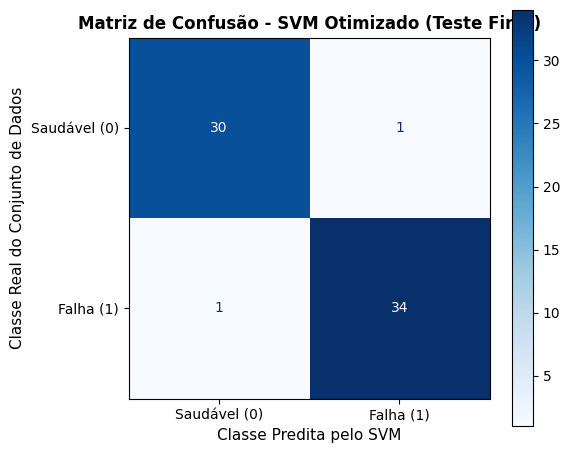


             SVM - DETALHAMENTO DA MATRIZ DE CONFUSÃO
Verdadeiros Negativos (Saudável -> Saudável) : 30
Falsos Positivos      (Saudável -> Falha)    : 1 (Alarmes Falsos)
Verdadeiros Positivos (Falha -> Falha)       : 34
Falsos Negativos      (Falha -> Saudável)    : 1 (Falhas Não Detectadas)
Amostras Totais Avaliadas                    : 66

             MÉTRICAS DE DESEMPENHO - SVM
             Métrica            Valor                                Descrição
Precision (Saudável)           0.9677            Precisão da classe 'Saudável'
   Recall (Saudável)           0.9677        Taxa de acerto na operação normal
 F1-Score (Saudável)           0.9677     Média harmônica da classe 'Saudável'
   Precision (Falha)           0.9714        Confiabilidade do alarme de falha
      Recall (Falha)           0.9714         Taxa de detecção de falhas reais
    F1-Score (Falha)           0.9714        Média harmônica da classe 'Falha'
     Acurácia Global           0.9697      Acurácia geral no

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score
)

# -------------------------------------------------------------------------
# 1. PREDIÇÃO E EXTRAÇÃO DOS COMPONENTES DA MATRIZ DE CONFUSÃO (SVM)
# -------------------------------------------------------------------------
# Extrai o modelo otimizado do GridSearchCV do SVM e realiza as predições
best_model_svm = grid_search_svm.best_estimator_
y_pred_svm = best_model_svm.predict(X_test)

# Obtém probabilidades ou pontuações de decisão para a curva ROC
if hasattr(best_model_svm, "predict_proba"):
    y_prob_svm = best_model_svm.predict_proba(X_test)[:, 1]
else:
    # Caso a flag probability=True não tenha sido definida no SVC, utiliza a função de decisão
    y_prob_svm = best_model_svm.decision_function(X_test)

# Obtém a matriz de confusão e extrai os termos escalares do SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)
tn_svm, fp_svm, fn_svm, tp_svm = cm_svm.ravel()

# -------------------------------------------------------------------------
# 2. FIGURA: MATRIZ DE CONFUSÃO (SVM)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
disp_svm = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=['Saudável (0)', 'Falha (1)']
)
disp_svm.plot(cmap='Blues', ax=ax, values_format='d')

ax.set_title("Matriz de Confusão - SVM Otimizado (Teste Final)", fontsize=12, fontweight='bold')
ax.set_xlabel("Classe Predita pelo SVM", fontsize=11)
ax.set_ylabel("Classe Real do Conjunto de Dados", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. IMPRESSÃO: DETALHAMENTO NUMÉRICO DA MATRIZ DE CONFUSÃO (SVM)
# -------------------------------------------------------------------------
print("\n" + "="*75)
print("             SVM - DETALHAMENTO DA MATRIZ DE CONFUSÃO")
print("="*75)
print(f"Verdadeiros Negativos (Saudável -> Saudável) : {tn_svm}")
print(f"Falsos Positivos      (Saudável -> Falha)    : {fp_svm} (Alarmes Falsos)")
print(f"Verdadeiros Positivos (Falha -> Falha)       : {tp_svm}")
print(f"Falsos Negativos      (Falha -> Saudável)    : {fn_svm} (Falhas Não Detectadas)")
print(f"Amostras Totais Avaliadas                    : {len(y_test)}")
print("="*75)

# -------------------------------------------------------------------------
# 4. CÁLCULO DAS MÉTRICAS E BOOTSTRAPPING PARA IC DA AUC-ROC (SVM)
# -------------------------------------------------------------------------
precision_healthy_svm = precision_score(y_test, y_pred_svm, pos_label=0)
recall_healthy_svm = recall_score(y_test, y_pred_svm, pos_label=0)
f1_healthy_svm = f1_score(y_test, y_pred_svm, pos_label=0)

precision_faulty_svm = precision_score(y_test, y_pred_svm, pos_label=1)
recall_faulty_svm = recall_score(y_test, y_pred_svm, pos_label=1)
f1_faulty_svm = f1_score(y_test, y_pred_svm, pos_label=1)

acuracia_global_svm = accuracy_score(y_test, y_pred_svm)
auc_roc_svm = roc_auc_score(y_test, y_prob_svm)

# Bootstrapping (1000x) para intervalo de confiança de 95% da AUC-ROC do SVM
n_bootstraps = 1000
auc_scores_bootstrap_svm = []
rng = np.random.RandomState(RANDOM_STATE)

for _ in range(n_bootstraps):
    indices = rng.choice(len(y_test), len(y_test), replace=True)
    y_test_resampled = y_test.iloc[indices]
    y_prob_resampled = y_prob_svm[indices]

    if len(np.unique(y_test_resampled)) < 2:
        continue

    auc_scores_bootstrap_svm.append(roc_auc_score(y_test_resampled, y_prob_resampled))

lower_bound_auc_svm = np.percentile(auc_scores_bootstrap_svm, 2.5)
upper_bound_auc_svm = np.percentile(auc_scores_bootstrap_svm, 97.5)

# -------------------------------------------------------------------------
# 5. IMPRESSÃO E ARMAZENAMENTO: TABELA DE MÉTRICAS DO SVM
# -------------------------------------------------------------------------
report_data_svm = [
    {"Métrica": "Precision (Saudável)", "Valor": f"{precision_healthy_svm:.4f}", "Descrição": "Precisão da classe 'Saudável'"},
    {"Métrica": "Recall (Saudável)", "Valor": f"{recall_healthy_svm:.4f}", "Descrição": "Taxa de acerto na operação normal"},
    {"Métrica": "F1-Score (Saudável)", "Valor": f"{f1_healthy_svm:.4f}", "Descrição": "Média harmônica da classe 'Saudável'"},
    {"Métrica": "Precision (Falha)", "Valor": f"{precision_faulty_svm:.4f}", "Descrição": "Confiabilidade do alarme de falha"},
    {"Métrica": "Recall (Falha)", "Valor": f"{recall_faulty_svm:.4f}", "Descrição": "Taxa de detecção de falhas reais"},
    {"Métrica": "F1-Score (Falha)", "Valor": f"{f1_faulty_svm:.4f}", "Descrição": "Média harmônica da classe 'Falha'"},
    {"Métrica": "Acurácia Global", "Valor": f"{acuracia_global_svm:.4f}", "Descrição": "Acurácia geral no conjunto de teste"},
    {"Métrica": "AUC-ROC", "Valor": f"{auc_roc_svm:.4f}", "Descrição": "Área sob a curva ROC"},
    {"Métrica": "IC 95% AUC-ROC", "Valor": f"[{lower_bound_auc_svm:.4f}, {upper_bound_auc_svm:.4f}]", "Descrição": "Intervalo de confiança (Bootstrap 1000x)"}
]

df_report_svm = pd.DataFrame(report_data_svm)

print("\n" + "="*75)
print("             MÉTRICAS DE DESEMPENHO - SVM")
print("="*75)
print(df_report_svm.to_string(index=False))
print("="*75)

# Pipeline - Melhores Hiperparâmetros

## Entrada: Classificador SVM

In [ ]:
import pandas as pd

# 1. Converte o dicionário completo de resultados do Grid Search do SVM em um DataFrame
results_svm = pd.DataFrame(grid_search_svm.cv_results_)

# 2. Mapeamento das colunas de interesse do SVM com nomes legíveis para publicação
cols_rename_svm = {
    'param_model__C': 'C (Regularização)',
    'param_model__kernel': 'Kernel',
    'param_model__gamma': 'Gamma',
    'param_model__degree': 'Grau (Degree)',
    'mean_test_score': 'Acurácia Média',
    'std_test_score': 'Desvio Padrão',
    'rank_test_score': 'Ranking'
}

# Mantém apenas as colunas presentes no dicionário de resultados
available_cols_svm = [col for col in cols_rename_svm.keys() if col in results_svm.columns]

# 3. Seleciona, renomeia, formata e exibe os 10 melhores cenários do SVM
top_10_grid_svm = results_svm[available_cols_svm].rename(columns=cols_rename_svm)

# Ordena pelo ranking do Grid Search
top_10_grid_svm = top_10_grid_svm.sort_values('Ranking').head(10)

# Preenche valores ausentes (ex: 'degree' para kernels que não utilizam esse parâmetro) com hífen
top_10_grid_svm = top_10_grid_svm.fillna('-')

# Formatação percentual para fácil leitura
top_10_grid_svm['Acurácia Média'] = (top_10_grid_svm['Acurácia Média'] * 100).map("{:.2f}%".format)
top_10_grid_svm['Desvio Padrão'] = (top_10_grid_svm['Desvio Padrão'] * 100).map("{:.2f}%".format)

print("\n" + "="*75)
print("       TOP 10 MELHORES COMBINAÇÕES DE HIPERPARÂMETROS DO SVM")
print("="*75)
print(top_10_grid_svm.to_string(index=False))
print("="*75)


       TOP 10 MELHORES COMBINAÇÕES DE HIPERPARÂMETROS DO SVM
 C (Regularização) Kernel Gamma Grau (Degree) Acurácia Média Desvio Padrão  Ranking
               1.0    rbf     1             -         99.33%         1.33%        1
               1.0    rbf scale             -         98.67%         1.63%        2
              10.0    rbf scale             -         98.67%         1.63%        2
               1.0    rbf  auto             -         98.67%         1.63%        2
              10.0    rbf  auto             -         98.67%         1.63%        2
              10.0    rbf     1             -         98.67%         1.63%        2
             100.0    rbf     1             -         98.67%         1.63%        2
               1.0    rbf   0.1             -         98.00%         2.67%        8
              10.0    rbf   0.1             -         98.00%         1.63%        8
             100.0    rbf   0.1             -         98.00%         1.63%        8


# Comparação de Desempenho KNN vs SVM

In [ ]:
import pandas as pd

df_comparativo = pd.DataFrame({
    'Métrica': [
        'Acurácia Global',
        'Precision (Falha)',
        'Recall (Falha)',
        'F1-Score (Falha)',
        'AUC-ROC'
    ],
    'KNN': [
        f"{acuracia_global_knn:.4f}",
        f"{precision_faulty_knn:.4f}",
        f"{recall_faulty_knn:.4f}",
        f"{f1_faulty_knn:.4f}",
        f"{auc_roc_knn:.4f}"
    ],
    'SVM': [
        f"{acuracia_global_svm:.4f}",
        f"{precision_faulty_svm:.4f}",
        f"{recall_faulty_svm:.4f}",
        f"{f1_faulty_svm:.4f}",
        f"{auc_roc_svm:.4f}"
    ],
    })

print("\n" + "="*60)
print("     QUADRO COMPARATIVO DE DESEMPENHO (KNN vs SVM)")
print("="*60)
print(df_comparativo.to_string(index=False))
print("="*60)


     QUADRO COMPARATIVO DE DESEMPENHO (KNN vs SVM)
          Métrica    KNN    SVM
  Acurácia Global 0.9545 0.9697
Precision (Falha) 0.9706 0.9714
   Recall (Falha) 0.9429 0.9714
 F1-Score (Falha) 0.9565 0.9714
          AUC-ROC 0.9982 0.9982


# PARTE 03 - MODELO DEEP LEARNING E COMPARAÇÃO

# Pipeline - Definição do Classificador e Verificação Inicial do Desempenho

## Entrada: Rede Neural Artificial - MLP

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Montagem do Pipeline unificado (Pré-processador + Classificador MLP)
pipeline_mlp = Pipeline([
    ('preprocessor', preprocessor),
    ('model', MLPClassifier(
        hidden_layer_sizes=(100,),  # 1 camada oculta com 100 neurônios (padrão)
        activation='relu',          # Função de ativação ReLU
        solver='adam',              # Otimizador baseado em gradiente
        max_iter=500,               # Limite máximo de épocas de treinamento
        random_state=42             # Garante reprodutibilidade nos pesos iniciais
    ))
])

# 2. Treinamento executado sobre os dados de TREINO JÁ FILTRADOS
pipeline_mlp.fit(X_train_filtered, y_train_filtered)

# 3. Predição sobre o conjunto de TESTE INTACTO (30% reservado)
y_pred_mlp = pipeline_mlp.predict(X_test)

# 4. Avaliação de Desempenho
print("=" * 60)
print("     AVALIAÇÃO DE DESEMPENHO DO MODELO MLP NO TESTE")
print("=" * 60)
print(f"Acurácia Global: {accuracy_score(y_test, y_pred_mlp) * 100:.2f}%\n")

print("Relatório de Classificação Detalhado:")
print(classification_report(y_test, y_pred_mlp, digits=4, target_names=['Saudável (0)', 'Falha (1)']))
print("=" * 60)

     AVALIAÇÃO DE DESEMPENHO DO MODELO MLP NO TESTE
Acurácia Global: 96.97%

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

Saudável (0)     0.9677    0.9677    0.9677        31
   Falha (1)     0.9714    0.9714    0.9714        35

    accuracy                         0.9697        66
   macro avg     0.9696    0.9696    0.9696        66
weighted avg     0.9697    0.9697    0.9697        66



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# DEFINIÇÃO DO PIPELINE COM MLP (Multi-Layer Perceptron)
# ==============================================================================
# A rede neural MLP é altamente sensível à escala dos dados e exige o StandardScaler.
# Definimos uma arquitetura inicial com 1 camada oculta de 100 neurônios e até 1000 épocas.
pipeline_full = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', MLPClassifier(
        hidden_layer_sizes=(100,),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# 1. Configuração da Validação Cruzada Estratificada (5 Folds)
# Mantém a mesma proporção de Saudável/Falha em cada um dos 5 blocos
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Execução da Validação Cruzada ESTRITAMENTE sobre o Treino Filtrado
scores = cross_val_score(
    pipeline_full,           # Pipeline que aplica o StandardScaler e o MLP em cada fold
    X_train_filtered,        # Matriz de treino filtrada (sem o conjunto de teste)
    y_train_filtered,        # Target de treino
    cv=cv_stratified,        # Estratificação garantida
    scoring='accuracy'       # Métrica de acurácia
)

# 3. Montagem do Relatório de Desempenho em DataFrame
data = {
    "Métrica": [f"Fold {i+1}" for i in range(len(scores))] + ["Acurácia Média", "Desvio Padrão"],
    "Valor": [f"{s*100:.2f}%" for s in scores] + [f"{scores.mean()*100:.2f}%", f"{scores.std()*100:.2f}%"]
}

df_cv_report = pd.DataFrame(data)

print("\n" + "="*70)
print("       RELATÓRIO DE VALIDAÇÃO CRUZADA ESTRATIFICADA (K-FOLD TREINO - MLP)")
print("="*70)
print(df_cv_report.to_string(index=False))
print("="*70)


       RELATÓRIO DE VALIDAÇÃO CRUZADA ESTRATIFICADA (K-FOLD TREINO - MLP)
       Métrica   Valor
        Fold 1  96.67%
        Fold 2  96.67%
        Fold 3  96.67%
        Fold 4 100.00%
        Fold 5  96.55%
Acurácia Média  97.31%
 Desvio Padrão   1.35%


# Pipeline - Otimização de Hiperparâmetros via Busca em Grade (Grid Search)

## Entrada: Rede Neural Artificial - MLP

In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Pipeline unificado com a Rede Neural Multilayer Perceptron (MLP)
pipeline_mlp = Pipeline([
    ('preprocessor', preprocessor),
    ('model', MLPClassifier(max_iter=1000, random_state=RANDOM_STATE))
])

# 2. Grade de hiperparâmetros para busca exaustiva na Rede Neural MLP
param_grid_mlp = {
    'model__hidden_layer_sizes': [(50,), (100,), (64, 32), (100, 50)], # Arquiteturas de camadas ocultas
    'model__activation': ['relu', 'tanh'],                              # Funções de ativação
    'model__solver': ['adam', 'sgd'],                                   # Otimizadores
    'model__alpha': [0.0001, 0.001, 0.01],                             # Termo de regularização L2
    'model__learning_rate_init': [0.001, 0.01]                          # Taxa de aprendizado inicial
}

# 3. Configuração da Validação Cruzada Estratificada
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 4. Instância do GridSearchCV para a MLP
grid_search_mlp = GridSearchCV(
    estimator=pipeline_mlp,
    param_grid=param_grid_mlp,
    cv=cv_stratified,         # Garante a proporção exata de classes em cada fold
    scoring='accuracy',       # Métrica de otimização
    n_jobs=-1                 # Uso de multiprocessamento
)

# 5. Ajuste EXCLUSIVO sobre os dados de treino filtrados
grid_search_mlp.fit(X_train_filtered, y_train_filtered)

# 6. Exibição e formatação tabular dos melhores hiperparâmetros
print("\n" + "="*60)
print("     MELHORES HIPERPARÂMETROS ENCONTRADOS PARA A MLP")
print("="*60)

formatted_params_mlp = {
    key.replace('model__', ''): [value]
    for key, value in grid_search_mlp.best_params_.items()
}
df_best_params_mlp = pd.DataFrame(formatted_params_mlp).melt(var_name='Parâmetro', value_name='Valor')
print(df_best_params_mlp.to_string(index=False))

print("="*60)
print(f"Melhor Acurácia Média no Treino (CV): {grid_search_mlp.best_score_ * 100:.2f}%")
print("="*60)


     MELHORES HIPERPARÂMETROS ENCONTRADOS PARA A MLP
         Parâmetro    Valor
        activation     relu
             alpha   0.0001
hidden_layer_sizes (64, 32)
learning_rate_init    0.001
            solver     adam
Melhor Acurácia Média no Treino (CV): 97.98%


# Pipeline -  Validação do Modelo ANN e Matriz de Confusão

## Entrada: Rede Neural Artificial - MLP

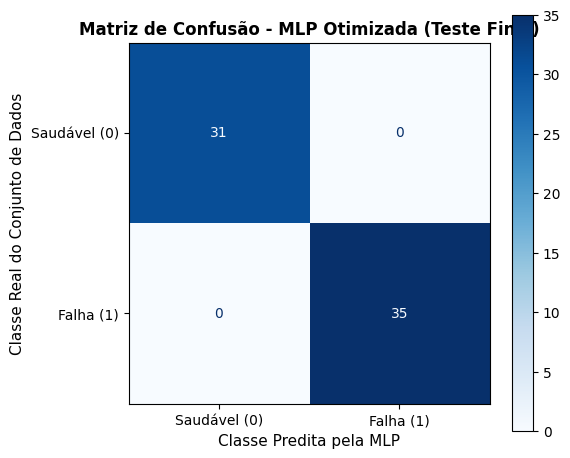


             MLP - DETALHAMENTO DA MATRIZ DE CONFUSÃO
Verdadeiros Negativos (Saudável -> Saudável) : 31
Falsos Positivos      (Saudável -> Falha)    : 0 (Alarmes Falsos)
Verdadeiros Positivos (Falha -> Falha)       : 35
Falsos Negativos      (Falha -> Saudável)    : 0 (Falhas Não Detectadas)
Amostras Totais Avaliadas                    : 66

             MÉTRICAS DE DESEMPENHO - MLP
             Métrica            Valor                                Descrição
Precision (Saudável)           1.0000            Precisão da classe 'Saudável'
   Recall (Saudável)           1.0000        Taxa de acerto na operação normal
 F1-Score (Saudável)           1.0000     Média harmônica da classe 'Saudável'
   Precision (Falha)           1.0000        Confiabilidade do alarme de falha
      Recall (Falha)           1.0000         Taxa de detecção de falhas reais
    F1-Score (Falha)           1.0000        Média harmônica da classe 'Falha'
     Acurácia Global           1.0000      Acurácia geral no

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score
)

# -------------------------------------------------------------------------
# 1. PREDIÇÃO E EXTRAÇÃO DOS COMPONENTES DA MATRIZ DE CONFUSÃO (MLP)
# -------------------------------------------------------------------------
# Extrai o modelo otimizado do GridSearchCV da MLP e realiza as predições
best_model_mlp = grid_search_mlp.best_estimator_
y_pred_mlp = best_model_mlp.predict(X_test)

# Obtém as probabilidades da classe positiva (1 - 'Falha') para a curva ROC
y_prob_mlp = best_model_mlp.predict_proba(X_test)[:, 1]

# Obtém a matriz de confusão e extrai os termos escalares da MLP
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
tn_mlp, fp_mlp, fn_mlp, tp_mlp = cm_mlp.ravel()

# -------------------------------------------------------------------------
# 2. FIGURA: MATRIZ DE CONFUSÃO (MLP)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
disp_mlp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=['Saudável (0)', 'Falha (1)']
)
disp_mlp.plot(cmap='Blues', ax=ax, values_format='d')

ax.set_title("Matriz de Confusão - MLP Otimizada (Teste Final)", fontsize=12, fontweight='bold')
ax.set_xlabel("Classe Predita pela MLP", fontsize=11)
ax.set_ylabel("Classe Real do Conjunto de Dados", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. IMPRESSÃO: DETALHAMENTO NUMÉRICO DA MATRIZ DE CONFUSÃO (MLP)
# -------------------------------------------------------------------------
print("\n" + "="*75)
print("             MLP - DETALHAMENTO DA MATRIZ DE CONFUSÃO")
print("="*75)
print(f"Verdadeiros Negativos (Saudável -> Saudável) : {tn_mlp}")
print(f"Falsos Positivos      (Saudável -> Falha)    : {fp_mlp} (Alarmes Falsos)")
print(f"Verdadeiros Positivos (Falha -> Falha)       : {tp_mlp}")
print(f"Falsos Negativos      (Falha -> Saudável)    : {fn_mlp} (Falhas Não Detectadas)")
print(f"Amostras Totais Avaliadas                    : {len(y_test)}")
print("="*75)

# -------------------------------------------------------------------------
# 4. CÁLCULO DAS MÉTRICAS E BOOTSTRAPPING PARA IC DA AUC-ROC (MLP)
# -------------------------------------------------------------------------
precision_healthy_mlp = precision_score(y_test, y_pred_mlp, pos_label=0)
recall_healthy_mlp = recall_score(y_test, y_pred_mlp, pos_label=0)
f1_healthy_mlp = f1_score(y_test, y_pred_mlp, pos_label=0)

precision_faulty_mlp = precision_score(y_test, y_pred_mlp, pos_label=1)
recall_faulty_mlp = recall_score(y_test, y_pred_mlp, pos_label=1)
f1_faulty_mlp = f1_score(y_test, y_pred_mlp, pos_label=1)

acuracia_global_mlp = accuracy_score(y_test, y_pred_mlp)
auc_roc_mlp = roc_auc_score(y_test, y_prob_mlp)

# Bootstrapping (1000x) para intervalo de confiança de 95% da AUC-ROC da MLP
n_bootstraps = 1000
auc_scores_bootstrap_mlp = []
rng = np.random.RandomState(RANDOM_STATE)

for _ in range(n_bootstraps):
    indices = rng.choice(len(y_test), len(y_test), replace=True)
    y_test_resampled = y_test.iloc[indices]
    y_prob_resampled = y_prob_mlp[indices]

    if len(np.unique(y_test_resampled)) < 2:
        continue

    auc_scores_bootstrap_mlp.append(roc_auc_score(y_test_resampled, y_prob_resampled))

lower_bound_auc_mlp = np.percentile(auc_scores_bootstrap_mlp, 2.5)
upper_bound_auc_mlp = np.percentile(auc_scores_bootstrap_mlp, 97.5)

# -------------------------------------------------------------------------
# 5. IMPRESSÃO E ARMAZENAMENTO: TABELA DE MÉTRICAS DA MLP
# -------------------------------------------------------------------------
report_data_mlp = [
    {"Métrica": "Precision (Saudável)", "Valor": f"{precision_healthy_mlp:.4f}", "Descrição": "Precisão da classe 'Saudável'"},
    {"Métrica": "Recall (Saudável)", "Valor": f"{recall_healthy_mlp:.4f}", "Descrição": "Taxa de acerto na operação normal"},
    {"Métrica": "F1-Score (Saudável)", "Valor": f"{f1_healthy_mlp:.4f}", "Descrição": "Média harmônica da classe 'Saudável'"},
    {"Métrica": "Precision (Falha)", "Valor": f"{precision_faulty_mlp:.4f}", "Descrição": "Confiabilidade do alarme de falha"},
    {"Métrica": "Recall (Falha)", "Valor": f"{recall_faulty_mlp:.4f}", "Descrição": "Taxa de detecção de falhas reais"},
    {"Métrica": "F1-Score (Falha)", "Valor": f"{f1_faulty_mlp:.4f}", "Descrição": "Média harmônica da classe 'Falha'"},
    {"Métrica": "Acurácia Global", "Valor": f"{acuracia_global_mlp:.4f}", "Descrição": "Acurácia geral no conjunto de teste"},
    {"Métrica": "AUC-ROC", "Valor": f"{auc_roc_mlp:.4f}", "Descrição": "Área sob a curva ROC"},
    {"Métrica": "IC 95% AUC-ROC", "Valor": f"[{lower_bound_auc_mlp:.4f}, {upper_bound_auc_mlp:.4f}]", "Descrição": "Intervalo de confiança (Bootstrap 1000x)"}
]

df_report_mlp = pd.DataFrame(report_data_mlp)

print("\n" + "="*75)
print("             MÉTRICAS DE DESEMPENHO - MLP")
print("="*75)
print(df_report_mlp.to_string(index=False))
print("="*75)

In [ ]:
import pandas as pd

# 1. Converte o dicionário completo de resultados do Grid Search do MLP em um DataFrame
results_mlp = pd.DataFrame(grid_search_mlp.cv_results_)

# 2. Mapeamento das colunas de interesse do MLP com nomes legíveis para publicação
cols_rename_mlp = {
    'param_model__hidden_layer_sizes': 'Camadas Ocultas',
    'param_model__activation': 'Ativação',
    'param_model__solver': 'Otimizador (Solver)',
    'param_model__alpha': 'Alpha (L2)',
    'param_model__learning_rate_init': 'Taxa de Aprendizado',
    'param_model__max_iter': 'Máx. Épocas',
    'mean_test_score': 'Acurácia Média',
    'std_test_score': 'Desvio Padrão',
    'rank_test_score': 'Ranking'
}

# Mantém apenas as colunas presentes no dicionário de resultados
available_cols_mlp = [col for col in cols_rename_mlp.keys() if col in results_mlp.columns]

# 3. Seleciona, renomeia, formata e exibe os 10 melhores cenários do MLP
top_10_grid_mlp = results_mlp[available_cols_mlp].rename(columns=cols_rename_mlp)

# Ordena pelo ranking do Grid Search
top_10_grid_mlp = top_10_grid_mlp.sort_values('Ranking').head(10)

# Preenche valores ausentes com hífen
top_10_grid_mlp = top_10_grid_mlp.fillna('-')

# Formatação percentual para fácil leitura
top_10_grid_mlp['Acurácia Média'] = (top_10_grid_mlp['Acurácia Média'] * 100).map("{:.2f}%".format)
top_10_grid_mlp['Desvio Padrão'] = (top_10_grid_mlp['Desvio Padrão'] * 100).map("{:.2f}%".format)

print("\n" + "="*75)
print("       TOP 10 MELHORES COMBINAÇÕES DE HIPERPARÂMETROS DO MLP")
print("="*75)
print(top_10_grid_mlp.to_string(index=False))
print("="*75)


       TOP 10 MELHORES COMBINAÇÕES DE HIPERPARÂMETROS DO MLP
Camadas Ocultas Ativação Otimizador (Solver)  Alpha (L2)  Taxa de Aprendizado Acurácia Média Desvio Padrão  Ranking
       (64, 32)     relu                adam      0.0001                0.001         97.98%         1.65%        1
       (64, 32)     relu                adam      0.0010                0.001         97.98%         1.65%        1
       (64, 32)     tanh                adam      0.0001                0.010         97.98%         1.65%        1
       (64, 32)     relu                adam      0.0100                0.001         97.98%         1.65%        1
       (64, 32)     tanh                adam      0.0010                0.010         97.98%         1.65%        1
          (50,)     relu                adam      0.0100                0.001         97.31%         1.35%        6
          (50,)     relu                adam      0.0010                0.001         97.31%         1.35%        6
         (

# Comparação de Desempenho KNN vs SVM vs MLP

In [ ]:
import pandas as pd

df_comparativo = pd.DataFrame({
    'Métrica': [
        'Acurácia Global',
        'Precision (Falha)',
        'Recall (Falha)',
        'F1-Score (Falha)',
        'AUC-ROC'
    ],
    'KNN': [
        f"{acuracia_global_knn:.4f}",
        f"{precision_faulty_knn:.4f}",
        f"{recall_faulty_knn:.4f}",
        f"{f1_faulty_knn:.4f}",
        f"{auc_roc_knn:.4f}"
    ],
    'SVM': [
        f"{acuracia_global_svm:.4f}",
        f"{precision_faulty_svm:.4f}",
        f"{recall_faulty_svm:.4f}",
        f"{f1_faulty_svm:.4f}",
        f"{auc_roc_svm:.4f}"
    ],
    'MLP': [
        f"{acuracia_global_mlp:.4f}",
        f"{precision_faulty_mlp:.4f}",
        f"{recall_faulty_mlp:.4f}",
        f"{f1_faulty_mlp:.4f}",
        f"{auc_roc_mlp:.4f}"
    ]
})

print("\n" + "="*60)
print("     QUADRO COMPARATIVO DE DESEMPENHO (KNN vs SVM vs MLP)")
print("="*60)
print(df_comparativo.to_string(index=False))
print("="*60)


     QUADRO COMPARATIVO DE DESEMPENHO (KNN vs SVM vs MLP)
          Métrica    KNN    SVM    MLP
  Acurácia Global 0.9545 0.9697 1.0000
Precision (Falha) 0.9706 0.9714 1.0000
   Recall (Falha) 0.9429 0.9714 1.0000
 F1-Score (Falha) 0.9565 0.9714 1.0000
          AUC-ROC 0.9982 0.9982 1.0000


# Pipeline - Validação Cruzada de Modelos Clássicos e MLP
##  Avaliação de Desempenho

In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# 1. Configuração do gerador do K-Fold Estratificado
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Lista com os classificadores clássicos e diferentes arquiteturas de ANN (MLP)
modelos = [
    ("Regressão Logística", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("Árvore de Decisão", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE)),
    ("KNN", KNeighborsClassifier()),
    ("SVM", SVC(random_state=RANDOM_STATE)),

    # --- MODELOS DE REDES NEURAIS (ANN / MLP) ---
    ("MLP (1 camada: 50)", MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=RANDOM_STATE)),
    ("MLP (1 camada: 100)", MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=RANDOM_STATE)),
    ("MLP (2 camadas: 64x32)", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=RANDOM_STATE)),
    ("MLP (2 camadas: 100x50)", MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=RANDOM_STATE))
]

resultados = []

# 3. Laço de avaliação comparativa dos algoritmos
for nome, modelo in modelos:

    # Pipeline unificado (Pré-processador + Modelo)
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", modelo)
    ])

    # Validação Cruzada Estratificada aplicada ESTRITAMENTE sobre o Treino Filtrado
    scores = cross_val_score(
        pipeline,
        X_train_filtered,      # Garante o isolamento do conjunto de teste (Holdout)
        y_train_filtered,      # Rótulos da classe (0: Saudável, 1: Falha)
        cv=cv_stratified,      # Preserva a proporção das classes em todos os folds
        scoring="accuracy"
    )

    resultados.append({
        "Modelo": nome,
        "Acurácia Média": scores.mean(),
        "Desvio Padrão": scores.std()
    })

# 4. Estruturação e ordenação do relatório comparativo
resultados_df = pd.DataFrame(resultados)
resultados_df["Acurácia Média (%)"] = (resultados_df["Acurácia Média"] * 100).round(2)
resultados_df["Desvio Padrão (%)"] = (resultados_df["Desvio Padrão"] * 100).round(2)

# Exibe ordenado do melhor para o pior desempenho
resultados_df = resultados_df.sort_values(by="Acurácia Média", ascending=False).drop(columns=["Acurácia Média", "Desvio Padrão"])

print("\n" + "="*70)
print("     BENCHMARK COMPARATIVO - MODELOS CLÁSSICOS VS REDES NEURAIS (ANN)")
print("="*70)
print(resultados_df.to_string(index=False))
print("="*70)


     BENCHMARK COMPARATIVO - MODELOS CLÁSSICOS VS REDES NEURAIS (ANN)
                 Modelo  Acurácia Média (%)  Desvio Padrão (%)
                    SVM               98.67               1.63
 MLP (2 camadas: 64x32)               97.98               1.65
                    KNN               97.33               2.49
     MLP (1 camada: 50)               97.31               1.35
    MLP (1 camada: 100)               97.31               1.35
MLP (2 camadas: 100x50)               97.31               1.35
      Árvore de Decisão               93.29               3.65
          Random Forest               93.29               4.71
    Regressão Logística               89.29               3.84


# PARTE 04 - APRESENTAÇÃO DO APLICATIVO

# CRIAÇÃO DO JOB DO MODELO E PREDIÇÃO

In [ ]:
import joblib
import pandas as pd

# -------------------------------------------------------------------------
# SALVAR O PIPELINE MLP TREINADO (Adicionado para resolver FileNotFoundError)
# -------------------------------------------------------------------------
# "grid_search_mlp" é o resultado da otimização de hiperparâmetros (GridSearchCV)
# e "best_estimator_" é o pipeline completo (preprocessor + modelo MLP) com os melhores parâmetros.
joblib.dump(grid_search_mlp.best_estimator_, 'pipeline_vibracao_mlp.pkl')

# -------------------------------------------------------------------------
# 1. CARREGAMENTO DO PIPELINE MLP
# -------------------------------------------------------------------------
modelo_mlp_carregado = joblib.load('pipeline_vibracao_mlp.pkl')

# -------------------------------------------------------------------------
# 2. DEFINIÇÃO DO MAPEAMENTO DE CLASSES DE VIBRAÇÃO
# -------------------------------------------------------------------------
# Mapeia os rótulos numéricos para as condições de operação reais
mapa_classes = {
    0: 'Saudável',
    1: 'Falha'
}

# -------------------------------------------------------------------------
# 3. NOVOS DADOS PARA INFERÊNCIA
# -------------------------------------------------------------------------
novo_sinal_maquina = pd.DataFrame({
    'rms': [4.85],          # Valor eficaz da aceleração
    'curtose': [4.15],      # Indicador de picos e transientes
    'fator_crista': [3.42],  # Razão entre pico e RMS
    'amp_1x': [2.10],        # Componente da rotação fundamental
    'amp_2x': [0.85],        # 2ª harmônica (desalinhamento)
    'amp_3x': [0.15]         # 3ª harmônica (folgas/impactos)
})

# -------------------------------------------------------------------------
# 4. PREDIÇÃO E EXIBIÇÃO FORMATADA DOS RESULTADOS
# -------------------------------------------------------------------------
predicao_num = modelo_mlp_carregado.predict(novo_sinal_maquina)[0]
probabilidades = modelo_mlp_carregado.predict_proba(novo_sinal_maquina)[0]

# Mapeia a classe numérica prevista para a descrição em texto
estado_predito = mapa_classes.get(predicao_num, f"Classe {predicao_num}")

print("\n--- RESULTADO DA ANÁLISE DE VIBRAÇÃO (MLP) ---")
print(f"Estado Operacional Predito: {estado_predito} (Código: {predicao_num})")
print("\nProbabilidade por Condição:")

for cls_num, proba in zip(modelo_mlp_carregado.classes_, probabilidades):
    nome_condicao = mapa_classes.get(cls_num, f"Classe {cls_num}")
    print(f" - {nome_condicao} (Classe {cls_num}): {proba:.2%}")


--- RESULTADO DA ANÁLISE DE VIBRAÇÃO (MLP) ---
Estado Operacional Predito: Falha (Código: 1)

Probabilidade por Condição:
 - Saudável (Classe 0): 0.00%
 - Falha (Classe 1): 100.00%


# ELABORAÇÃO DO APLICATIVO WEB DE DIAGNÓSTICO

## INSTALAÇÃO STREAMLIT

In [ ]:
# Instala o Streamlit e o localtunnel via npm (silencioso para evitar travamentos)
!pip install -q streamlit
!npm install -g localtunnel > /dev.null 2>&1

## LIMPA O SERVIDOR DE STREAMLIT

In [ ]:
# Encerra qualquer servidor Streamlit e Cloudflare antigo que esteja rodando na porta 8501
!pkill -f streamlit
!pkill -f cloudflared

# Reescreve o arquivo app_sinal_bruto.py no disco

## CRIA A APLICAÇÃO WEB DE DIAGNOSTICO DE FALHA

In [ ]:
%%writefile app_sinal_bruto.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.io import loadmat
from scipy.fft import fft, fftfreq
from scipy.stats import kurtosis

st.set_page_config(page_title="Diagnóstico de Vibração - Sinal Bruto", page_icon="⚡", layout="wide")

def extrair_features_sinal_bruto(sinal_triaxial, fs=1000, rpm=2980, N=4096):
    """
    Função de extração de atributos com compatibilidade do nome chamado no App.
    """
    if sinal_triaxial.shape[0] < sinal_triaxial.shape[1]:
        sinal_triaxial = sinal_triaxial.T

    # 1. Resultante Euclidiana
    res = np.linalg.norm(sinal_triaxial[:, :3], axis=1)

    # 2. Atributos no Tempo
    rms = np.sqrt(np.mean(res**2))
    curt = kurtosis(res)
    fator_crista = np.max(np.abs(res)) / rms if rms > 0 else 0.0

    # 3. Atributos na Frequência (FFT com Janela de Hanning)
    f_rotacao = rpm / 60.0
    sinal_cent = res[:N] - np.mean(res[:N])
    janela = np.hanning(len(sinal_cent))
    sinal_janelado = sinal_cent * janela

    yf = fft(sinal_janelado)
    xf = fftfreq(len(sinal_cent), 1/fs)

    amplitude = (2.0 / np.sum(janela)) * np.abs(yf[:N//2])
    frequencias = xf[:N//2]

    features = {'rms': rms, 'curtose': curt, 'fator_crista': fator_crista}

    for h in [1, 2, 3]:
        f_alvo = h * f_rotacao
        idx = np.where((frequencias >= f_alvo - 3) & (frequencias <= f_alvo + 3))[0]
        features[f'amp_{h}x'] = np.max(amplitude[idx]) if len(idx) > 0 else 0.0

    return pd.DataFrame([features]), res, frequencias, amplitude


# Carrega o Pipeline MLP Treinado
try:
    pipeline_mlp = joblib.load('pipeline_vibracao_mlp.pkl')
    modelo_carregado = True
except Exception:
    modelo_carregado = False

st.title("⚡ Machine Learning para Detecção de Anomalia")
st.markdown("Envie o arquivo **.mat** triaxial da máquina ($5000$ pontos a $1000\\text{ Hz}$) para processamento automático.")

if not modelo_carregado:
    st.error("⚠️ O arquivo 'pipeline_vibracao_mlp.pkl' não foi localizado no diretório raiz.")
else:
    file_upload = st.file_uploader("Selecione o arquivo de vibração (.mat)", type=["mat"])

    if file_upload is not None:
        mat_data = loadmat(file_upload)
        chave = [k for k in mat_data.keys() if not k.startswith('__')][0]
        sinal_bruto = mat_data[chave]

        # Chamada da função garantida
        df_features, res, freqs, amps = extrair_features_sinal_bruto(sinal_bruto)

        st.subheader("📊 Características do Sinal")
        st.dataframe(df_features.round(4))

        # Diagnóstico com o Pipeline
        pred_code = pipeline_mlp.predict(df_features)[0]
        proba = pipeline_mlp.predict_proba(df_features)[0]

        st.subheader("📋 Diagnóstico Operacional")
        if pred_code == 1:
            st.error(f"🚨 **Diagnóstico:** FALHA DETECTADA (Probabilidade: {proba[1]:.2%})")
        else:
            st.success(f"✅ **Diagnóstico:** MÁQUINA SAUDÁVEL (Probabilidade: {proba[0]:.2%})")

        # --- SEÇÃO DE GRÁFICOS ---
        st.subheader("📈 Análise Gráfica dos Sinais e Indicadores")

        col1, col2, col3 = st.columns([2.2, 2.2, 1.6])

        # 1. Gráfico Temporal da Resultante
        with col1:
            st.markdown("**Sinal Resultante da Vibração**")
            fig1, ax1 = plt.subplots(figsize=(5, 3.5))
            ax1.plot(res[:1000], color='#1f77b4', linewidth=1.2)
            ax1.set_ylim(0, 5)
            ax1.set_xlim(0, 1000)
            ax1.set_xlabel("Amostras", fontsize=9)
            ax1.set_ylabel("Amplitude", fontsize=9)
            ax1.grid(True, linestyle=':', alpha=0.6)
            plt.tight_layout()
            st.pyplot(fig1)

        # 2. Espectro FFT
        with col2:
            st.markdown("**Harmônicas de Frequência**")
            mask = freqs <= 180
            fig2, ax2 = plt.subplots(figsize=(5, 3.5))
            ax2.plot(freqs[mask], amps[mask], color='#ff7f0e', linewidth=1.2)
            ax2.set_ylim(0, 0.50)
            ax2.set_xlim(0, 180)
            ax2.xaxis.set_major_locator(ticker.MultipleLocator(25))
            ax2.set_xlabel("Frequência (Hz)", fontsize=9)
            ax2.set_ylabel("Amplitude", fontsize=9)
            ax2.grid(True, linestyle=':', alpha=0.6)
            plt.tight_layout()
            st.pyplot(fig2)

        # 3. Indicadores Estatísticos
        with col3:
            st.markdown("**Indicadores Estatísticos**")
            rms_val = df_features['rms'].iloc[0]
            curt_val = df_features['curtose'].iloc[0]
            cf_val = df_features['fator_crista'].iloc[0]

            fig3, ax3 = plt.subplots(figsize=(3.8, 3.5))
            metricas = ['RMS', 'Curtose', 'F. Crista']
            valores = [rms_val, curt_val, cf_val]
            cores = ['#2ca02c', '#d62728', '#9467bd']

            barras = ax3.bar(metricas, valores, color=cores, width=0.45, edgecolor='black', alpha=0.85)
            ax3.set_ylim(-0.5, 5.5)
            ax3.set_ylabel("Valor do Indicador", fontsize=9)
            ax3.grid(True, axis='y', linestyle=':', alpha=0.6)

            for barra in barras:
                altura = barra.get_height()
                ax3.annotate(f'{altura:.2f}',
                             xy=(barra.get_x() + barra.get_width() / 2, altura),
                             xytext=(0, 3),
                             textcoords="offset points",
                             ha='center', va='bottom', fontsize=8, fontweight='bold')

            plt.tight_layout()
            st.pyplot(fig3)

Overwriting app_sinal_bruto.py


## CRIA O LINK DA APLICAÇÃO WEB

In [ ]:
import subprocess
import time
import re

# 1. Baixa o executável do Cloudflare Tunnel (se ainda não existir)
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared

# 2. Inicia o Streamlit em segundo plano apontando para o app de sinal bruto
streamlit_proc = subprocess.Popen([
    "streamlit", "run", "app_sinal_bruto.py",
    "--server.headless", "true",
    "--server.port", "8501"
])

# Aguarda 4 segundos para garantir a subida do servidor local
time.sleep(4)

# 3. Inicia o túnel da Cloudflare apontando para a porta do Streamlit
tunnel_proc = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

# 4. Captura a URL pública nos logs de inicialização sem travar a execução
url_encontrada = False
print("⚡ Aguardando a geração da URL pública do sistema...")

# Tolerância de até 15 segundos verificando os logs do Cloudflare
for _ in range(30):
    # Lê as linhas disponíveis no buffer sem bloquear o script
    line = tunnel_proc.stderr.readline()
    if line:
        match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
        if match:
            public_url = match.group(0)
            print("\n" + "=" * 65)
            print("🚀 INTERFACE WEB DO STREAMLIT ONLINE E ESTÁVEL!")
            print(f"🔗 Acesse o sistema pelo link: {public_url}")
            print("=" * 65 + "\n")
            url_encontrada = True
            break
    time.sleep(0.5)

if not url_encontrada:
    print("⚠️ Não foi possível obter a URL automaticamente.")
    print("Verifique se o arquivo 'app_sinal_bruto.py' e o modelo '.pkl' estão na mesma pasta.")

⚡ Aguardando a geração da URL pública do sistema...

🚀 INTERFACE WEB DO STREAMLIT ONLINE E ESTÁVEL!
🔗 Acesse o sistema pelo link: https://newsletters-tap-york-wave.trycloudflare.com

